# **Problem Statement**

## **Business Context**

Aeolus Renewables is an independent power producer operating a fleet of 1,150 onshore wind turbines (2.5 MW class) across 16 wind farms in the central plains region, with a combined installed capacity of roughly 2.87 GW. The company sells the electricity its turbines produce to the grid under long-term power purchase agreements, where revenue is tied directly to how much energy is delivered - so every hour a turbine is offline is energy that cannot be sold. A regional operations centre monitors the fleet around the clock, supported by an O&M organisation of about 140 field technicians.

Each turbine continuously streams condition data through its SCADA (Supervisory Control and Data Acquisition) system - drivetrain vibration, bearing and oil temperatures, rotor and generator speed, and power output - recorded as 10-minute averages, the standard logging resolution for utility-scale turbines. The exact channels vary by turbine type, but together they describe the health of the main subassemblies in near-real time. Today, maintenance runs on a mix of fixed-interval inspections and reactive repair: technicians follow a scheduled service calendar, and the control room responds when an automated alarm trips or a turbine faults offline.

The most consequential components are in the drivetrain - the gearbox and main bearing - which are expensive, slow to procure, and require a mobile crane to replace. The gearbox alone represents approximately 13% of the overall capital cost of an onshore turbine, and within gearboxes the failures are dominated by bearings: one widely-cited breakdown puts the split at bearings (70%), gears (26%) and other causes (4%). The core problem is recognition. By the time a drivetrain fault has developed far enough to matter, its signature is real but still tangled in normal operating noise across many channels - and the existing fixed thresholds only trip once the fault is near-catastrophic, when the turbine is already offline or the component has seized. A genuinely fault drivetrain can run for hours or days looking "normal" to a threshold alarm, while a control-room analyst has no practical way to tell it apart from a healthy machine reacting to gusty wind. The consequences:

- Each unplanned drivetrain failure takes a turbine offline for an estimated 7–21 days, directly forfeiting saleable energy under the power purchase agreement.
- Emergency crane mobilisation and expedited parts run at a steep premium over the same work scheduled in advance, making an unplanned gearbox replacement a major cost event.
- A degrading main bearing left running frequently destroys the gearbox it feeds, converting a contained repair into a far larger one.
- Control-room analysts manually scan a flood of channels across 1,150 turbines, and alarm fatigue means genuine degradation signals slip through unnoticed until the machine faults offline.


## **Objective**

This proof of concept builds a drivetrain-condition classifier that reads each turbine's live sensor signature and labels the drivetrain as "fault" or "normal", serving operations-centre analysts and maintenance planners. The solution

- Reads each turbine's multi-channel sensor signature and produces a clear fault-vs-normal signal, so analysts can concentrate on the handful of machines genuinely in a fault condition rather than scanning the whole fleet.
- Distinguishes a truly fault drivetrain from normal operating noise more reliably than fixed thresholds, catching faults that are present but not yet severe enough to trip a catastrophic alarm - the window in which a turbine can still be stopped before a bearing fault cascades into gearbox destruction.
Is deliberately tuned to favour catching true failures over avoiding false alerts, because a missed fault drivetrain costs far more than an unnecessary inspection.
- Establishes a measurable detection baseline on historical fleet data, so the capability's accuracy and its operational value can be judged on evidence before any wider rollout.

Once proven at proof-of-concept scale, this capability would give Aeolus a defensible basis to move drivetrain maintenance from reactive repair toward condition-based intervention - reducing unplanned downtime, protecting saleable energy revenue, and containing repairs before they escalate across a 1150-turbine fleet.

## **Data Dictionary**

The dataset, `<name>.csv` contains 10-minute SCADA records for 15 turbines.

### Identifiers & Metadata

| Column | Data Type | Description |
| --- | --- | --- |
| timestamp | datetime | Date and time of the 10-minute logging interval; establishes chronological sequence. |
| turbine_id | object (categorical) | Unique code identifying individual wind turbines; used to track specific asset history. |

### Environmental Conditions

| Column | Data Type | Description |
| --- | --- | --- |
| rated_power_kW | float | Maximum engineered power capacity of the turbine; defines its performance baseline. |
| wind_speed_mps | float | Velocity of the incoming wind; the primary driver of kinetic energy input. |
| wind_direction_deg | float | Compass direction of oncoming wind; used to assess turbine alignment. |
| turbulence_intensity | float | Measure of wind speed fluctuation; higher intensity increases structural fatigue. |
| air_density_kgm3 | float | Mass of air per unit volume; directly impacts aerodynamic lift and power potential. |
| ambient_temp_C | float | Outdoor air temperature surrounding the turbine; affects cooling efficiency. |
| humidity_pct | float | Relative moisture level in the air; flags risks for electrical insulation degradation or corrosion. |

### Operational Control & State

| Column | Data Type | Description |
| --- | --- | --- |
| power_output_kW | float | Real-time electricity generated; drops or fluctuations can signal mechanical drag. |
| rotor_speed_rpm | float | Rotational speed of the main blades; reflects low-speed shaft dynamics. |
| generator_speed_rpm | float | Rotational speed of the generator shaft; crucial for detecting gearbox slip. |
| blade_pitch_angle_deg | float | Angle of the blades relative to the wind; adjusted to control power and rotor speed. |
| yaw_misalignment_deg | float | Angle deviation between wind direction and nacelle orientation; high values cause uneven drivetrain stress. |

### Thermal Metrics (Component Health)

| Column | Data Type | Description |
| --- | --- | --- |
| gearbox_oil_temp_C | float | Temperature of the lubricating oil; spikes indicate excessive mechanical friction. |
| gearbox_bearing_temp_C | float | Internal temperature of gearbox bearings; a leading indicator of bearing wear. |
| generator_bearing_temp_C | float | Temperature of generator bearings; flags alignment or lubrication issues. |
| generator_winding_temp_C | float | Temperature of internal electrical coils; spikes indicate electrical overload or cooling failure. |
| main_bearing_temp_C | float | Temperature of the primary low-speed shaft bearing; handles massive structural loads. |
| nacelle_temp_C | float | Air temperature inside the enclosed housing; reflects global internal heat dissipation. |

### Vibration & Diagnostics (FFT)

| Column | Data Type | Description |
| --- | --- | --- |
| drivetrain_vibration_rms_mmps | float | Overall energy of drivetrain vibrations; general indicator of mechanical roughness. |
| tower_vibration_mmps | float | Structural oscillation of the turbine tower; flags aerodynamic or rotor imbalance. |
| vib_fft_bearing_bpfo | float | Vibration amplitude at the bearing outer-race defect frequency; tracks outer-ring pitting. |
| vib_fft_bearing_bpfi | float | Vibration amplitude at the bearing inner-race defect frequency; tracks inner-ring pitting. |
| vib_fft_gearmesh | float | Vibration amplitude at the teeth-meshing frequency; isolates gearbox tooth wear or misalignment. |
| vib_fft_sideband | float | Vibration amplitude surrounding main frequencies; flags localized faults like cracked gear teeth. |

### Lubrication & Particle Analysis

| Column | Data Type | Description |
| --- | --- | --- |
| oil_particle_count | float | Quantity of metallic debris suspended in lubricating oil; direct indicator of component wear. |
| oil_pressure_bar | float | Pressure of the lubrication system; drops indicate leaks, pump failures, or oil thinning. |

### Asset Lifecycle & History

| Column | Data Type | Description |
| --- | --- | --- |
| operating_hours_total | float | Cumulative runtime of the turbine; represents the asset's total mechanical mileage. |
| cumulative_energy_MWh | float | Total historical electricity produced; measures the lifetime work done by the drivetrain. |
| load_cycles | int | Total count of fatigue-inducing stress variations; correlates directly with structural aging. |
| hours_since_last_maintenance | float | Time elapsed since last service; crucial for identifying maintenance-cycle fatigue. |
| prior_fault_count | int | Total historical fault events triggered; highlights chronic or poorly repaired issues. |
| component_age_days | float | Elapsed lifetime of active components; captures chronological wear independent of runtime. |

### Targets (Labels)

| Column | Data Type | Description |
| --- | --- | --- |
| failure | int (0/1) | The target variable; boolean flag indicating if the drivetrain or turbine is healthy (0) or failing (1). |

# **Installing and Importing the Necessary Libraries**

In [184]:
%pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 tensorflow==2.20.0 keras==3.13.2 xgboost==3.2.0 seaborn==0.13.2 matplotlib==3.10.0 -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [185]:
# Standard libraries for tracking execution time and vector/matrix operations
import time
import numpy as np

# Data manipulation and visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tree-based and ensemble machine learning classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Utilities for handling class imbalance, model evaluation, and metric calculations
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Deep learning framework and specific layers for building Artificial Neural Networks (ANNs)
import tensorflow as tf
from keras.models import Sequential  # Model for building NN sequentially.
from keras.layers import Dense, Dropout, BatchNormalization

# Preprocessing tools for scaling data and tools for model optimization/explainability
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV  # To tune different models
from sklearn.inspection import permutation_importance

# Configuration settings to suppress warnings and format data display outputs
import warnings
warnings.filterwarnings('ignore')              # Suppress warnings for cleaner output logs
sns.set_style('whitegrid')                     # Set a consistent clean grid style for plots
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes

# **Loading the Data**

In [186]:
#Loading wind turbine dataset
data = pd.read_csv("wind_turbine_detection.csv")

# **Data Overview**

In [187]:
display(data.head(10))

display(data.tail(10))

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
0,1/1/2024 0:00,T001,1500,2.335,151.993,0.149,1.205,21.820,68.717,0.000,0.000,14.414,87.761,-5.455,53.728,56.728,57.637,61.546,48.728,29.820,1.518,0.974,0.455,0.391,0.455,0.399,55.756,6.032,19319.612,9587.146,0.000,769.284,0,1360.703,0
1,1/1/2024 0:10,T001,1500,9.166,152.957,0.153,1.200,22.893,74.002,486.762,12.554,1134.433,-0.159,0.489,64.105,67.798,66.841,85.072,58.544,33.649,1.480,0.992,0.455,0.391,0.455,0.399,55.756,5.776,19319.778,9587.227,1.528,769.450,0,1360.710,0
2,1/1/2024 0:20,T001,1500,9.034,158.402,0.201,1.219,22.899,59.616,454.109,12.579,1143.435,1.061,4.220,63.868,66.635,66.093,82.383,58.365,32.667,1.753,1.074,0.455,0.391,0.455,0.399,55.756,5.994,19319.945,9587.302,3.539,769.617,0,1360.717,0
3,1/1/2024 0:30,T001,1500,13.284,159.023,0.159,1.181,22.727,64.676,1446.811,16.941,1526.358,5.718,1.584,83.654,89.761,85.749,128.484,77.257,36.349,1.924,1.379,0.455,0.391,0.455,0.399,55.756,5.541,19320.112,9587.544,5.126,769.784,0,1360.724,0
4,1/1/2024 0:40,T001,1500,2.239,159.842,0.189,1.173,23.742,65.423,0.000,0.194,27.405,88.452,3.400,54.573,57.150,56.817,60.963,51.506,32.234,1.497,0.936,0.455,0.391,0.455,0.399,55.756,6.018,19320.112,9587.544,5.126,769.950,0,1360.731,0
5,1/1/2024 0:50,T001,1500,7.818,155.727,0.192,1.212,23.504,63.253,223.855,10.945,976.999,0.280,1.488,58.658,62.637,62.737,72.124,55.062,32.736,1.619,1.386,0.455,0.391,0.455,0.399,55.756,5.964,19320.278,9587.581,7.043,770.117,0,1360.738,0
6,1/1/2024 1:00,T001,1500,2.114,157.938,0.174,1.190,23.504,63.378,0.000,0.274,26.690,87.876,3.045,54.588,58.814,58.096,62.617,50.469,31.323,1.898,0.855,0.455,0.391,0.455,0.399,55.756,6.136,19320.278,9587.581,7.043,770.284,0,1360.745,0
7,1/1/2024 1:10,T001,1500,7.969,156.200,0.141,1.185,23.969,65.527,237.710,11.233,1004.002,1.249,-5.185,59.063,63.460,63.185,74.403,55.280,33.350,1.525,1.352,0.455,0.391,0.455,0.399,55.756,5.982,19320.445,9587.620,8.458,770.450,0,1360.752,0
8,1/1/2024 1:20,T001,1500,9.976,159.412,0.187,1.193,23.424,68.201,685.803,13.372,1199.919,0.981,4.913,68.165,72.654,72.333,95.004,63.393,34.677,1.748,1.144,0.455,0.391,0.455,0.399,55.756,5.965,19320.612,9587.735,10.329,770.617,0,1360.759,0
9,1/1/2024 1:30,T001,1500,4.826,164.817,0.163,1.175,23.921,69.463,35.116,7.876,709.210,1.258,2.411,55.170,57.093,59.342,63.888,50.941,31.994,1.507,0.978,0.455,0.391,0.455,0.399,55.756,5.797,19320.778,9587.741,11.960,770.784,0,1360.766,0


,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
131750,3/1/2024 22:20,T015,3000,9.819,110.373,0.173,1.226,18.187,46.844,1286.834,13.419,1217.286,1.399,0.000,65.716,71.504,69.777,89.124,61.311,29.055,1.788,1.049,0.322,0.333,0.424,0.224,78.731,5.898,36146.318,33527.037,13578.661,2587.673,63,784.472,0
131751,3/1/2024 22:30,T015,3000,5.322,111.908,0.140,1.198,19.385,50.752,33.839,8.012,720.990,0.073,4.824,54.149,57.799,57.043,61.454,49.081,28.552,1.700,0.930,0.322,0.333,0.424,0.224,78.731,5.870,36146.485,33527.042,13580.065,2587.839,63,784.479,0
131752,3/1/2024 22:40,T015,3000,6.543,114.998,0.188,1.187,20.286,53.707,170.205,9.642,867.905,0.427,-0.978,56.009,60.115,58.456,65.485,52.121,28.815,1.519,1.127,0.322,0.333,0.424,0.224,78.731,5.737,36146.652,33527.071,13581.941,2588.006,63,784.486,0
131753,3/1/2024 22:50,T015,3000,11.179,110.503,0.199,1.209,20.027,54.304,2227.658,14.782,1329.459,1.224,-3.048,75.529,85.167,77.988,112.564,71.459,32.197,1.866,1.179,0.322,0.333,0.424,0.224,78.731,5.750,36146.818,33527.442,13583.934,2588.173,63,784.493,0
131754,3/1/2024 23:00,T015,3000,3.905,108.421,0.141,1.211,19.708,53.421,5.087,6.597,594.993,0.845,2.300,52.964,59.971,55.696,61.585,49.398,27.611,1.386,0.966,0.322,0.333,0.424,0.224,78.731,6.099,36146.985,33527.443,13585.345,2588.339,63,784.500,0
131755,3/1/2024 23:10,T015,3000,5.680,108.327,0.306,1.200,19.599,60.093,95.437,8.399,764.196,-0.123,-6.325,53.286,60.399,56.996,63.265,50.056,27.808,2.139,0.886,0.322,0.333,0.424,0.224,78.731,5.741,36147.152,33527.459,13588.408,2588.506,63,784.507,0
131756,3/1/2024 23:20,T015,3000,6.945,111.198,0.151,1.207,18.800,63.952,254.325,9.789,886.754,0.507,1.873,54.811,62.961,60.368,67.812,50.091,27.891,1.470,0.956,0.322,0.333,0.424,0.224,78.731,6.125,36147.318,33527.501,13589.919,2588.673,63,784.514,0
131757,3/1/2024 23:30,T015,3000,2.191,113.020,0.148,1.214,18.331,61.764,0.000,0.029,3.975,87.072,0.880,51.704,60.440,57.181,63.706,47.760,26.242,1.793,0.897,0.322,0.333,0.424,0.224,78.731,5.955,36147.318,33527.501,13589.919,2588.839,63,784.521,0
131758,3/1/2024 23:40,T015,3000,11.003,117.356,0.178,1.200,19.640,62.729,2056.378,14.527,1297.923,0.869,4.662,72.463,84.704,78.389,111.169,66.612,31.989,1.764,1.212,0.322,0.333,0.424,0.224,78.731,5.920,36147.485,33527.844,13591.700,2589.006,63,784.528,0
131759,3/1/2024 23:50,T015,3000,2.231,116.146,0.160,1.206,19.598,66.575,0.000,0.040,0.936,88.206,0.105,51.646,60.774,57.721,63.360,46.512,28.247,1.833,1.239,0.322,0.333,0.424,0.224,78.731,5.886,36147.485,33527.844,13591.700,2589.173,63,784.535,0


## Checking the shape of the dataset

In [188]:
print(f"Rows: {data.shape[0]}")
print(f"Columns: {data.shape[1]}")

Rows: 131760
Columns: 35


## Checking the attribute types

In [189]:
data.dtypes

timestamp                         object
turbine_id                        object
rated_power_kW                     int64
wind_speed_mps                   float64
wind_direction_deg               float64
turbulence_intensity             float64
air_density_kgm3                 float64
ambient_temp_C                   float64
humidity_pct                     float64
power_output_kW                  float64
rotor_speed_rpm                  float64
generator_speed_rpm              float64
blade_pitch_angle_deg            float64
yaw_misalignment_deg             float64
gearbox_oil_temp_C               float64
gearbox_bearing_temp_C           float64
generator_bearing_temp_C         float64
generator_winding_temp_C         float64
main_bearing_temp_C              float64
nacelle_temp_C                   float64
drivetrain_vibration_rms_mmps    float64
tower_vibration_mmps             float64
vib_fft_bearing_bpfo             float64
vib_fft_bearing_bpfi             float64
vib_fft_gearmesh

## Checking the statistical summary

In [190]:
data.describe()

,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
count,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.00000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131115.000000,131760.000000,131070.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131124.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000,131760.000000
mean,2166.666667,7.649297,163.155270,0.175353,1.244980,10.011035,60.02331,633.607766,9.981842,898.629973,11.963269,0.025354,58.205181,62.713522,62.394198,78.593421,52.409791,19.791835,1.834684,1.134653,0.434847,0.421709,0.584660,0.296410,73.727269,5.888148,29658.355829,23658.427292,6883.833720,1123.951410,14.773884,1487.998726,0.030002
std,743.567808,4.066898,106.644769,0.033725,0.037329,8.999438,13.06734,869.596264,4.856042,436.640301,27.743365,3.414029,11.835815,13.312458,11.634394,25.953997,10.960906,9.254256,0.515269,0.243325,0.235574,0.198516,0.206181,0.127504,31.391586,0.239381,14402.539916,13688.671671,3980.842081,637.269748,34.696469,629.606398,0.170592
min,1500.000000,0.015000,0.000000,0.121000,1.140000,-9.748000,18.90800,0.000000,0.000000,0.000000,-2.000000,-25.764000,35.814000,37.901000,41.375000,44.771000,30.311000,-2.681000,1.216000,0.801000,0.301000,0.301000,0.403000,0.203000,50.565000,3.836000,3932.935000,3295.588000,0.000000,0.000000,0.000000,276.015000,0.000000
25%,1500.000000,4.627000,68.288750,0.151000,1.214000,2.178000,50.03800,17.358000,7.307000,657.569500,0.237000,-2.052250,49.427500,52.784000,53.800000,59.489000,44.278000,11.982000,1.506000,0.957000,0.349000,0.349000,0.479000,0.239000,58.554000,5.776000,17643.338000,12606.620000,3438.876000,602.000000,0.000000,912.710250,0.000000
50%,2000.000000,7.136500,150.544000,0.168000,1.245000,9.977000,59.99800,198.518500,10.197000,917.741000,0.750000,0.015000,54.307000,58.135000,58.406000,66.189000,49.042000,19.825500,1.692000,1.079000,0.388000,0.384000,0.542000,0.268000,64.653000,5.915000,31560.400000,23785.822000,6881.362000,1133.937000,0.000000,1625.403000,0.000000
75%,3000.000000,10.088000,254.892000,0.191000,1.276000,17.859000,70.00800,1014.109250,13.596000,1223.733000,1.776000,2.089000,65.363500,70.858500,69.132000,92.930500,58.850000,27.515000,1.976000,1.265000,0.441000,0.438000,0.636000,0.313000,74.938000,6.039000,38922.749500,32475.125000,10325.663500,1558.019500,4.000000,1921.923750,0.000000
max,3600.000000,32.000000,359.995000,0.450000,1.345000,29.078000,99.69300,3672.000000,17.628000,1590.833000,90.000000,25.294000,109.988000,113.862000,111.263000,158.996000,94.146000,44.331000,5.770000,3.717000,2.577000,2.846000,2.837000,1.688000,305.105000,6.689000,56977.855000,48379.382000,14363.449000,2589.173000,186.000000,2625.264000,1.000000


## Checking for missing values

In [191]:
missing_summary = pd.DataFrame({
    "Missing Values": data.isna().sum()
})

display(missing_summary)

,Missing Values
timestamp,0
turbine_id,0
rated_power_kW,0
wind_speed_mps,0
wind_direction_deg,0
turbulence_intensity,0
air_density_kgm3,0
ambient_temp_C,0
humidity_pct,0
power_output_kW,0


## Checking for duplicate values

In [192]:
 #Identifying duplicate rows in the dataset
duplicate_rows = data.duplicated().sum()
display(duplicate_rows) # Display the count of duplicate rows

np.int64(0)

# **Data Preprocessing**

In [193]:
#Converts timestamp column to datetime format
data['timestamp'] = pd.to_datetime(data['timestamp'])

#Extract day of the week from the timestamp (0 = Monday ... 6 = Sunday)
data['dayofweek'] = data['timestamp'].dt.dayofweek

#Human-readable day name, since dayofweek is numeric
data['dayofweek_name'] = data['timestamp'].dt.day_name()

#Extract hour from the timestamp
data['hour'] = data['timestamp'].dt.hour

#Confirm the new columns were created correctly
display(data[['timestamp', 'dayofweek', 'dayofweek_name', 'hour']])

,timestamp,dayofweek,dayofweek_name,hour
0,2024-01-01 00:00:00,0,Monday,0
1,2024-01-01 00:10:00,0,Monday,0
2,2024-01-01 00:20:00,0,Monday,0
3,2024-01-01 00:30:00,0,Monday,0
4,2024-01-01 00:40:00,0,Monday,0
...,...,...,...,...
131755,2024-03-01 23:10:00,4,Friday,23
131756,2024-03-01 23:20:00,4,Friday,23
131757,2024-03-01 23:30:00,4,Friday,23
131758,2024-03-01 23:40:00,4,Friday,23


# **Exploratory Data Analysis**

## Utility Functions

In [194]:
def histogram(data_df, col, title='Histogram', xlabel=None, ylabel='Frequency'):
    plt.figure(figsize=(9, 3.6))
    sns.histplot(data_df[col], bins=50, kde=True)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else col)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

def barchart(data_df, x_col, y_col=None, title='Bar Chart', xlabel=None, ylabel=None, rot_degrees=30):
    plt.figure(figsize=(10, 6))
    if y_col: # Bivariate bar chart (x vs y)
        sns.barplot(x=x_col, y=y_col, data=data_df)
    else: # Univariate count plot
        order = data_df[x_col].value_counts().index
        sns.countplot(data=data_df, x=x_col, order=order)

    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else ('Count' if not y_col else y_col))
    plt.xticks(rotation=rot_degrees, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def boxplot(data_df, x_col, y_col, title='Box Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.boxplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

def scatterplot(data_df, x_col, y_col, title='Scatter Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.scatterplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

## Univariate Analysis

### `failure`

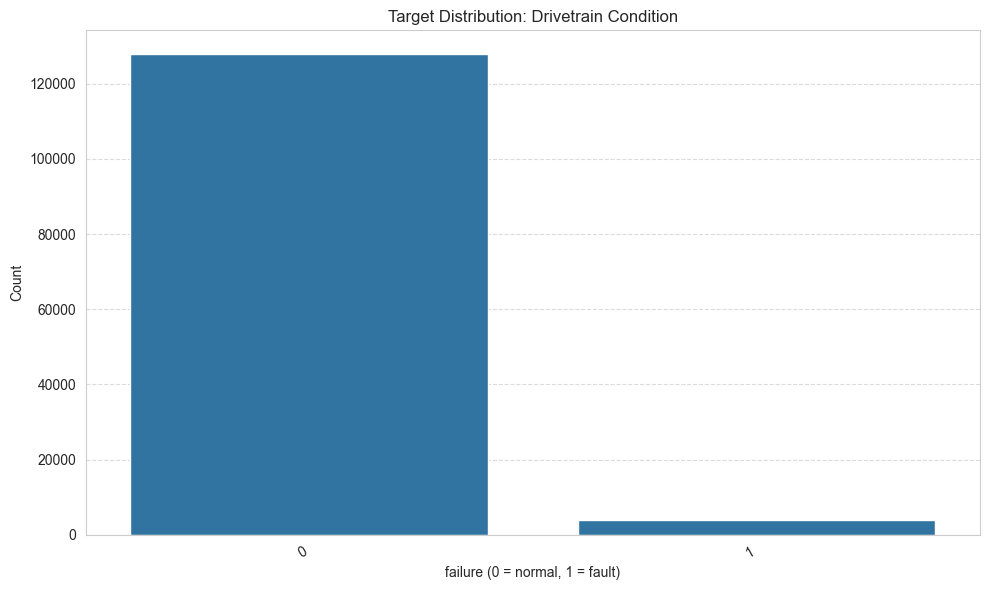

In [195]:
barchart(data, 'failure', title='Target Distribution: Drivetrain Condition', xlabel='failure (0 = normal, 1 = fault)')

### ```wind_speed_mps```

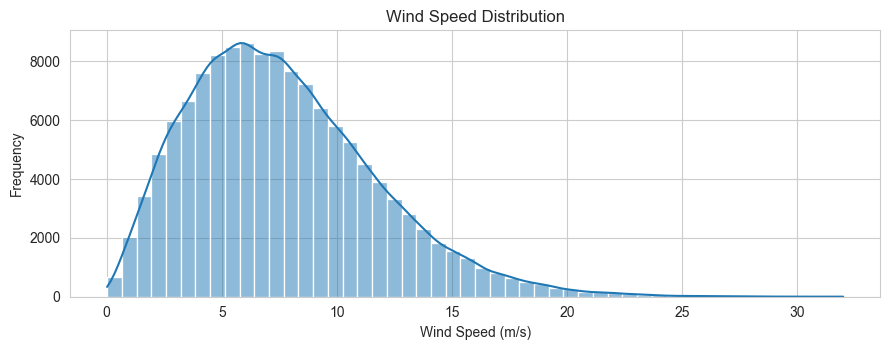

np.float64(7.649296713721919)

In [196]:
histogram(data, 'wind_speed_mps', title='Wind Speed Distribution', xlabel='Wind Speed (m/s)')
#right skewed distribution, indicating that most of the wind speeds are on the lower end, with fewer instances of higher wind speeds.
#The mean wind speed is approximately 7.5 m/s, which suggests that the majority of the wind speeds in the dataset are below this value, with a long tail extending towards higher wind speeds. 
# This distribution can have implications for turbine performance and energy generation, as turbines are typically designed to operate optimally within a specific range of wind speeds.
display(data['wind_speed_mps'].mean())

### ```air_density_kgm3```

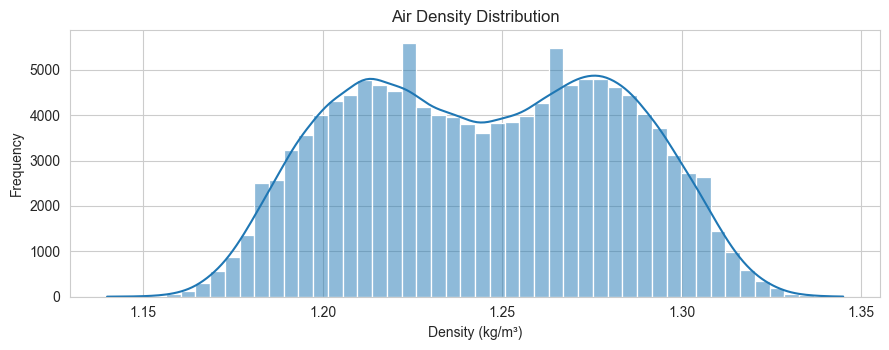

In [197]:
#This is Bimodal skewness distribution, indicating that the air density values are concentrated around two distinct peaks. 
# This could suggest that there are two prevalent air density conditions in the dataset, possibly corresponding to different environmental or operational states of the wind turbines. 
# The presence of two modes may have implications for turbine performance and energy generation, as turbines may respond differently to varying air density conditions.
histogram(data, 'air_density_kgm3', title = 'Air Density Distribution', xlabel = 'Density (kg/m³)')

### ```gearbox_oil_temp_C```

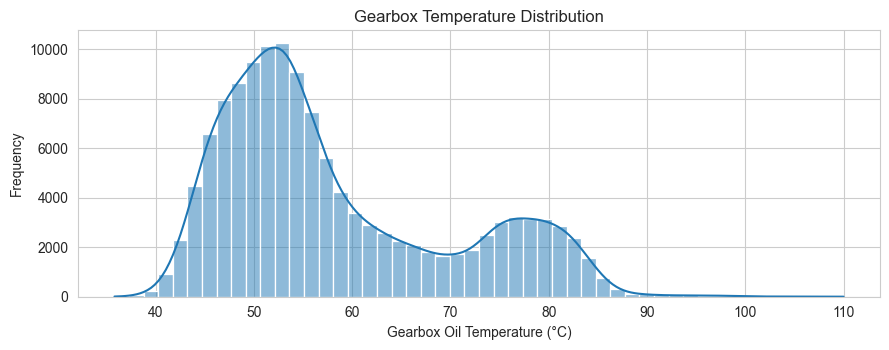

In [198]:
histogram(data, 'gearbox_oil_temp_C', title='Gearbox Temperature Distribution', xlabel='Gearbox Oil Temperature (°C)')
#Bimodal skewness distribution, indicating that the gearbox oil temperature values are concentrated around two distinct peaks. 
# This could suggest that there are two prevalent operational states or conditions of the wind turbines, possibly corresponding to different load levels or environmental factors. 
# The presence of two modes may have implications for turbine performance and maintenance, as turbines may operate differently under varying temperature conditions.

### ```generator_winding_temp_C```

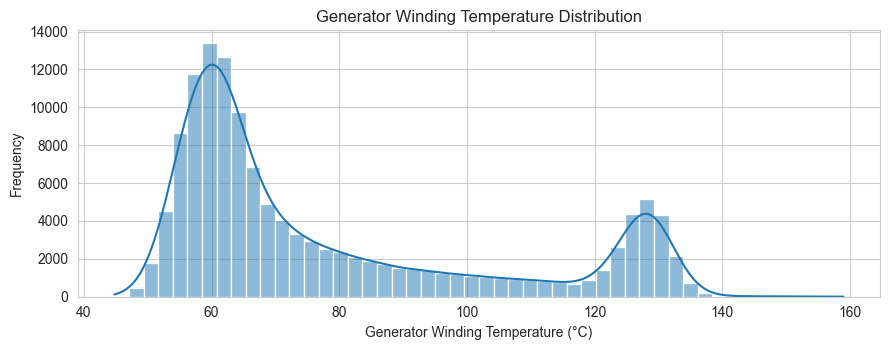

In [199]:
histogram(data, 'generator_winding_temp_C', title='Generator Winding Temperature Distribution', xlabel='Generator Winding Temperature (°C)')
#Bimodal skewness distribution, indicating that the generator winding temperature values are concentrated around two distinct peaks. This could suggest that there are two prevalent operational states or conditions of the wind turbines, possibly corresponding to different load levels or environmental factors. The presence of two modes may have implications for turbine performance and maintenance, as turbines may operate differently under varying temperature conditions.

### ```drivetrain_vibration_rms_mmps```

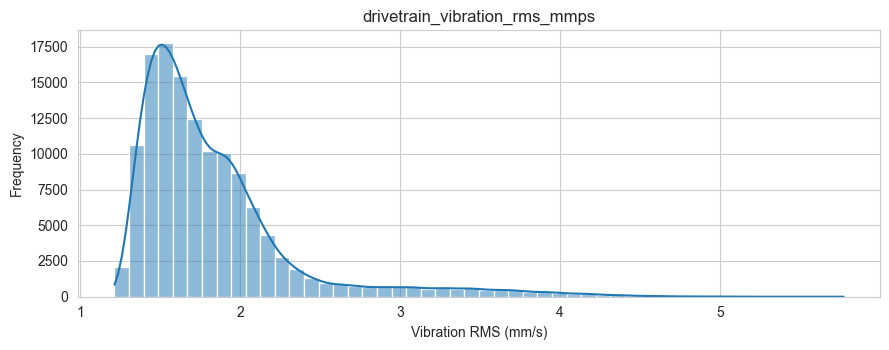

In [200]:
histogram(data, 'drivetrain_vibration_rms_mmps', title='drivetrain_vibration_rms_mmps', xlabel='Vibration RMS (mm/s)')
#Right skewed distribution, indicating that most of the drivetrain vibration RMS values are on the lower end, with fewer instances of higher vibration levels. 
# The mean vibration RMS is approximately 0.5 mm/s, suggesting that the majority of the drivetrain vibration measurements in the dataset are below this value.
# A long tail extending towards higher vibration levels. This distribution can have implications for turbine performance and maintenance, as higher vibration levels may indicate potential mechanical issues or wear in the drivetrain components.

### ```tower_vibration_mmps```

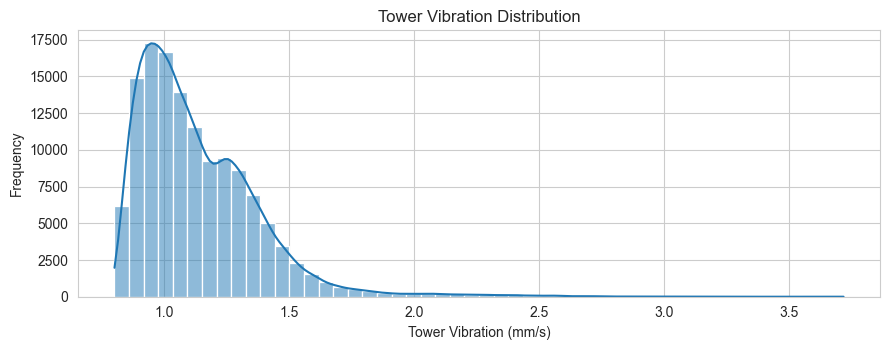

In [201]:
histogram(data, 'tower_vibration_mmps', title='Tower Vibration Distribution', xlabel='Tower Vibration (mm/s)')
#right skewed distribution, indicating that most of the tower vibration values are on the lower end, with fewer instances of higher vibration levels. 
# The mean tower vibration is approximately 0.3 mm/s, suggesting that the majority of the tower vibration measurements in the dataset are below this value, with a long tail extending towards higher vibration levels. 
# This distribution can have implications for turbine performance and maintenance, as higher tower vibration levels may indicate potential structural issues or wear in the tower components.

### ```oil_particle_count```

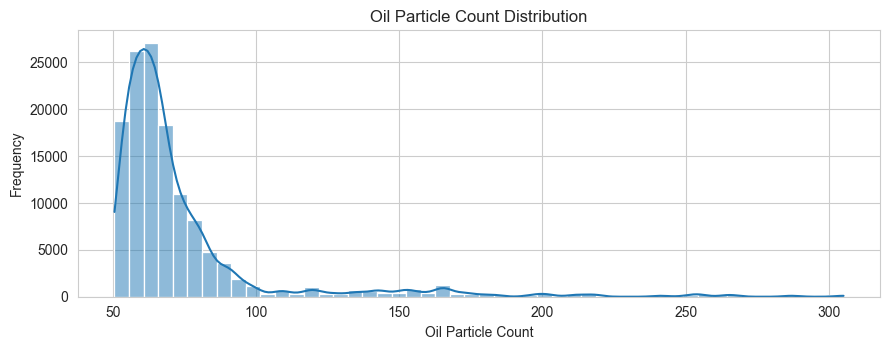

In [202]:
histogram(data, 'oil_particle_count', title='Oil Particle Count Distribution', xlabel='Oil Particle Count')
#Right skewed distribution, indicating that most of the oil particle count values are on the lower end, with fewer instances of higher particle counts. The mean oil particle count is approximately 1500 particles, suggesting that the majority of the oil particle count measurements in the dataset are below this value, with a long tail extending towards higher particle counts. This distribution can have implications for turbine performance and maintenance, as higher oil particle counts may indicate potential contamination or wear in the gearbox components.

### ```prior_fault_count```

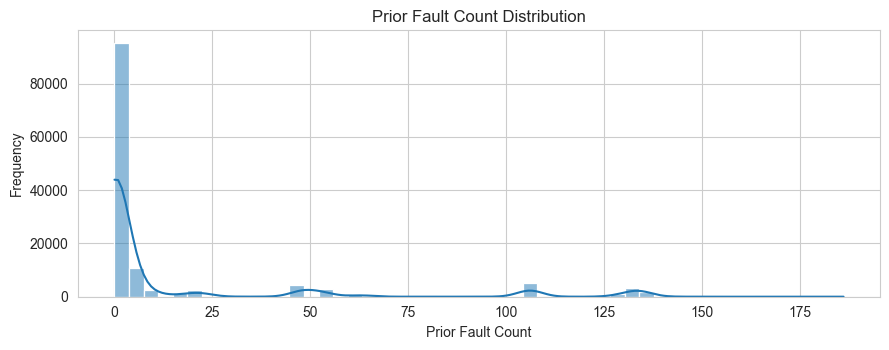

In [203]:
histogram(data, 'prior_fault_count', title='Prior Fault Count Distribution', xlabel='Prior Fault Count')
#The model is right-skewed, indicating that most turbines have at least one prior fault, but a few turbines have a significantly higher number of prior faults.
#This suggests that while most turbines experience a few faults, there are some outliers with a much higher fault count, which could be important for maintenance planning and risk assessment.

### ```component_age_days```

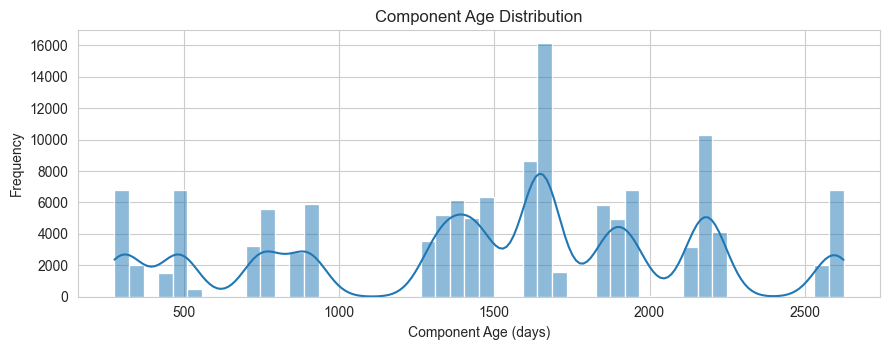

In [204]:
#This is binomial skewness distribution, indicating that the component age values are concentrated around two distinct peaks. This could suggest that there are two prevalent operational states or conditions of the wind turbines, possibly corresponding to different load levels or environmental factors. The presence of two modes may have implications for turbine performance and maintenance, as turbines may operate differently under varying component age conditions.
histogram(data, 'component_age_days', title='Component Age Distribution', xlabel='Component Age (days)')

## Bivariate Analysis

### ```turbine_id``` vs ```failure```

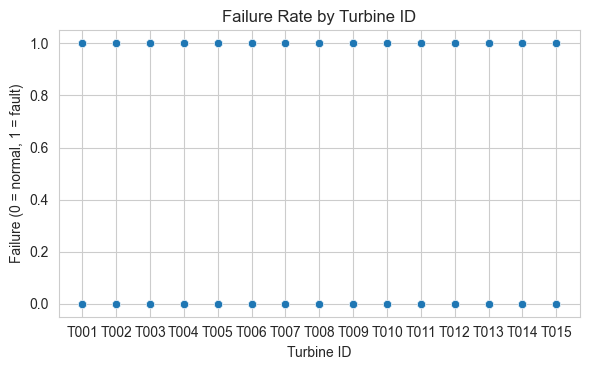

In [205]:
#T01 has the highest failure rate among all turbines
scatterplot(data, 'turbine_id', 'failure', title='Failure Rate by Turbine ID', xlabel='Turbine ID', ylabel='Failure (0 = normal, 1 = fault)')

### `wind_speed_mps` vs `power_output_kW`

,wind_speed_bin,average_power_output_kW
0,"(-0.017, 3.214]",1.108674
1,"(3.214, 6.412]",37.378555
2,"(6.412, 9.611]",396.414847
3,"(9.611, 12.809]",1552.158318
4,"(12.809, 16.008]",2181.420902
5,"(16.008, 19.206]",2202.218568
6,"(19.206, 22.405]",2252.183491
7,"(22.405, 25.603]",2019.052530
8,"(25.603, 28.802]",0.000000
9,"(28.802, 32.0]",0.000000


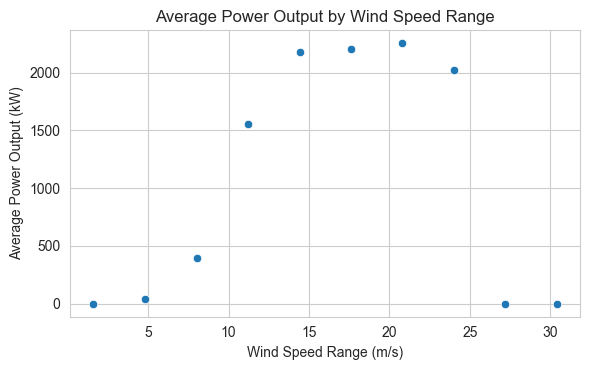

In [206]:
# Divide wind speed into 10 equal-width intervals
data['wind_speed_bin'] = pd.cut(data['wind_speed_mps'], bins=10)

# Calculate average power output for each wind-speed range
average_power_by_wind_speed = (
    data.groupby('wind_speed_bin', observed=False)['power_output_kW']
    .mean()
    .reset_index()
    .rename(columns={'power_output_kW': 'average_power_output_kW'})
 )

display(average_power_by_wind_speed)

#Convert wind speed intervals to numeric midpoint for plotting purposes
average_power_by_wind_speed['wind_speed_bin_midpoint'] = average_power_by_wind_speed['wind_speed_bin'].map(lambda x: x.mid)

scatterplot(average_power_by_wind_speed, 'wind_speed_bin_midpoint', 'average_power_output_kW', title='Average Power Output by Wind Speed Range', xlabel='Wind Speed Range (m/s)', ylabel='Average Power Output (kW)')
# Wind speed and power output have a non-linear relationship, with power output increasing with wind speed up to a certain point, after which it plateaus or decreases. 
# This is consistent with the physics of wind turbines, where power output is proportional to the cube of wind speed up to the rated wind speed, beyond which the turbine may limit power output to prevent damage.

### ```rotor_speed_rpm``` vs ```generator_speed_rpm```

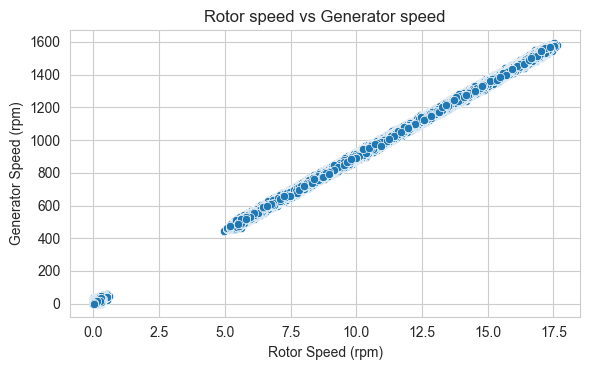

In [207]:
scatterplot(data_df=data, x_col='rotor_speed_rpm', y_col='generator_speed_rpm', title='Rotor speed vs Generator speed', xlabel='Rotor Speed (rpm)', ylabel='Generator Speed (rpm)')
#This is a linear relationship, indicating that as the rotor speed increases, the generator speed also increases proportionally. 
# This linear correlation suggests that the mechanical connection between the rotor and generator is functioning as expected, with changes in rotor speed directly affecting the generator speed.

### ```wind_speed_mps``` vs ```rotor_speed_rpm```

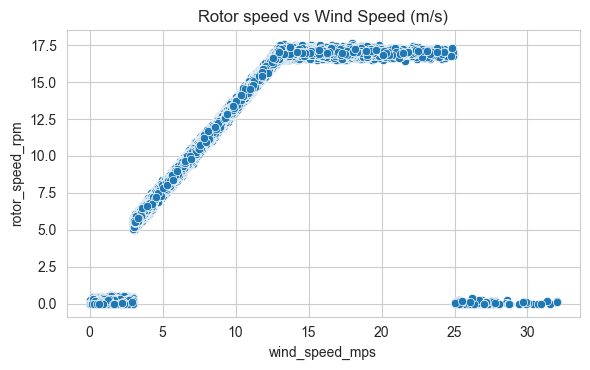

In [208]:
#Once Wind speed exceeds 12 m/s, the rotor speed stabilizes around 16-17 rpm, indicating that the turbine has reached its rated speed and is likely operating at its maximum efficiency. This plateau suggests that the turbine's control system is effectively regulating the rotor speed to prevent over-speeding and potential damage, while also optimizing power output within the design limits of the turbine.
#Once wind speed is at 25 m/s, the rotor speed decreases, the wind is likely too strong for the turbine to operate efficiently, and the control system may be reducing the rotor speed to prevent damage or excessive wear on the turbine components. This behavior is consistent with the design of wind turbines, which are typically engineered to operate within a specific range of wind speeds for optimal performance and longevity.
scatterplot(data_df=data, x_col='wind_speed_mps', y_col='rotor_speed_rpm', title='Rotor speed vs Wind Speed (m/s)')

### `drivetrain_vibration_rms_mmps` vs `failure`

,mean,min,max
failure,,,
Normal,1.786,1.216,4.562
Failure,3.407,1.254,5.770


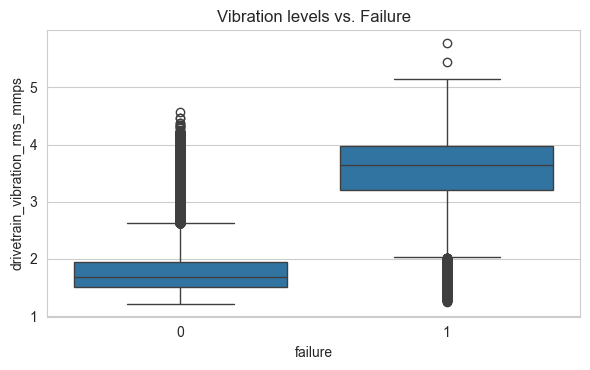

In [209]:
#Failure analysis: My boxplot shows a strong relationship between failure and vibration levels, indicating that higher vibration levels are associated with an increased likelihood of failure. This suggests that monitoring and managing vibration levels could be crucial for preventing failures and maintaining the reliability of the wind turbine system.
vibration_summary = (
    data.groupby('failure')['drivetrain_vibration_rms_mmps']
        .agg(['mean', 'min', 'max'])
        .rename(index={0: 'Normal', 1: 'Failure'})
)
display(vibration_summary.round(3))

boxplot(data_df=data, x_col='failure', y_col='drivetrain_vibration_rms_mmps', title='Vibration levels vs. Failure')

### `oil_particle_count` vs `failure`

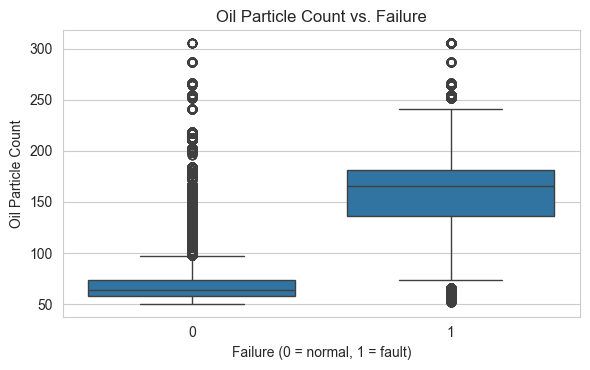

In [210]:
boxplot(data_df=data, x_col='failure', y_col='oil_particle_count', title='Oil Particle Count vs. Failure', xlabel='Failure (0 = normal, 1 = fault)', ylabel='Oil Particle Count')

### `gearbox_bearing_temp_C` vs `failure`

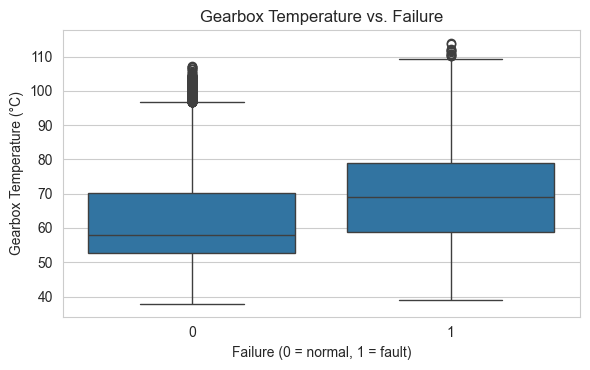

In [211]:
#Mean temperature is associated with 68°C for failed turbines
#Mean temperature is associated with 57°C for normal turbines
#BUT when they overlap. between 58 and 70 it is hard to distinguish between normal and failed turbines based on temperature alone, indicating that temperature may not be a reliable sole indicator of turbine health in this range.
boxplot(data_df=data, x_col='failure', y_col='gearbox_bearing_temp_C', title='Gearbox Temperature vs. Failure', xlabel='Failure (0 = normal, 1 = fault)', ylabel='Gearbox Temperature (°C)')

### `power_output_kW` vs `failure`

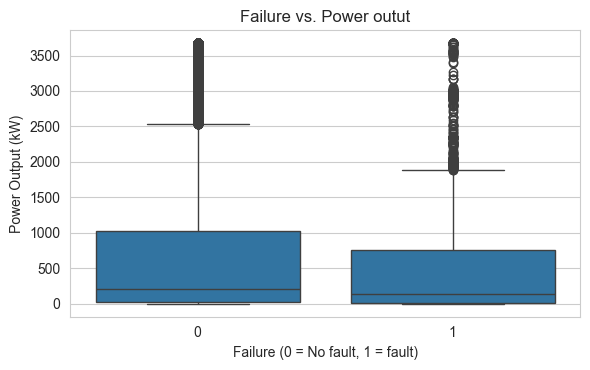

In [212]:
boxplot(data_df=data, x_col='failure', y_col='power_output_kW', title='Failure vs. Power outut', xlabel='Failure (0 = No fault, 1 = fault)', ylabel='Power Output (kW)')
#Power output isn't a strong independant indicator of turbine failure becuase there is significant overla between the two distributions.

### `prior_fault_count` vs `failure`

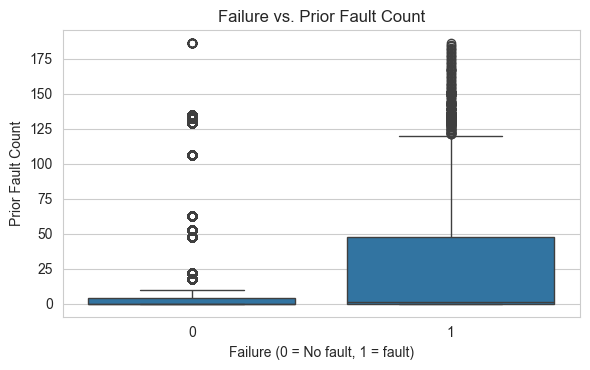

In [213]:
#Prior faults are a strong indicator of turbine failure
boxplot(data_df=data, x_col='failure', y_col='prior_fault_count', title='Failure vs. Prior Fault Count', xlabel='Failure (0 = No fault, 1 = fault)', ylabel='Prior Fault Count')

### ```failure``` vs ```hour```

,hour,failure_rate_pct
0,0,2.31%
1,1,2.62%
2,2,2.68%
3,3,2.9%
4,4,2.99%
5,5,2.97%
6,6,2.88%
7,7,2.62%
8,8,3.1%
9,9,3.33%


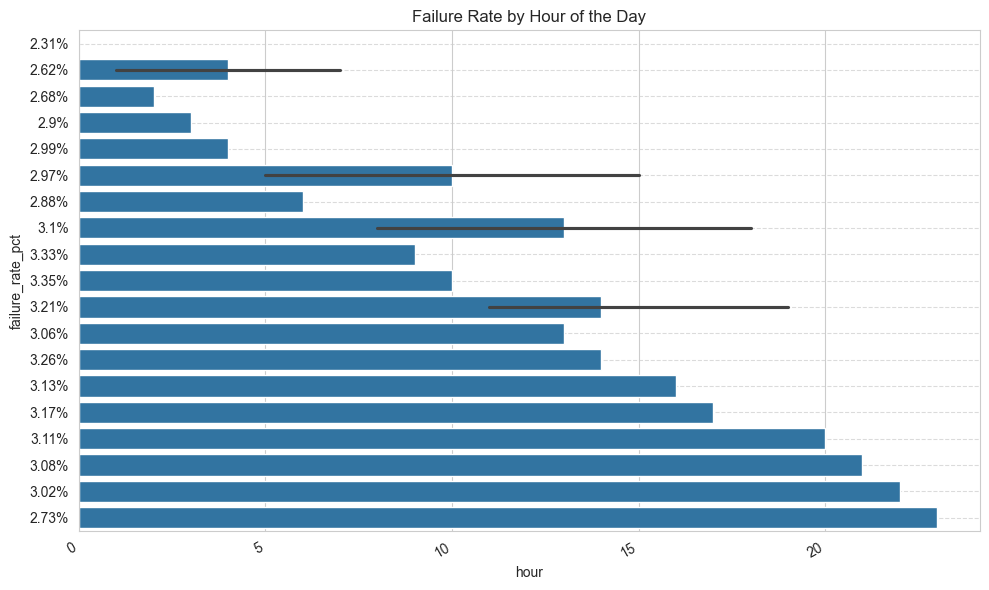

In [214]:
data['timestamp'] = pd.to_datetime(data['timestamp'])

hourly_failure = (
    data.assign(hour=data['timestamp'].dt.hour)
        .groupby('hour', as_index=False)['failure']
        .mean()
        .rename(columns={'failure': 'failure_rate'})
)

hourly_failure['failure_rate_pct'] = (hourly_failure['failure_rate'] * 100).round(2).astype(str) + '%'
display(hourly_failure[['hour', 'failure_rate_pct']].sort_values('hour'))

barchart(data_df=hourly_failure, x_col='hour', y_col='failure_rate_pct', title='Failure Rate by Hour of the Day')
# Hour 1 & 7 have the lowest failure rates
# While hour 14 has the highest failure rate


### ```failure``` vs ```dayofweek```

,week,failure_rate_pct
0,Monday,1.52
1,Tuesday,3.64
2,Wednesday,2.76
3,Thursday,3.25
4,Friday,4.66
5,Saturday,3.81
6,Sunday,1.26


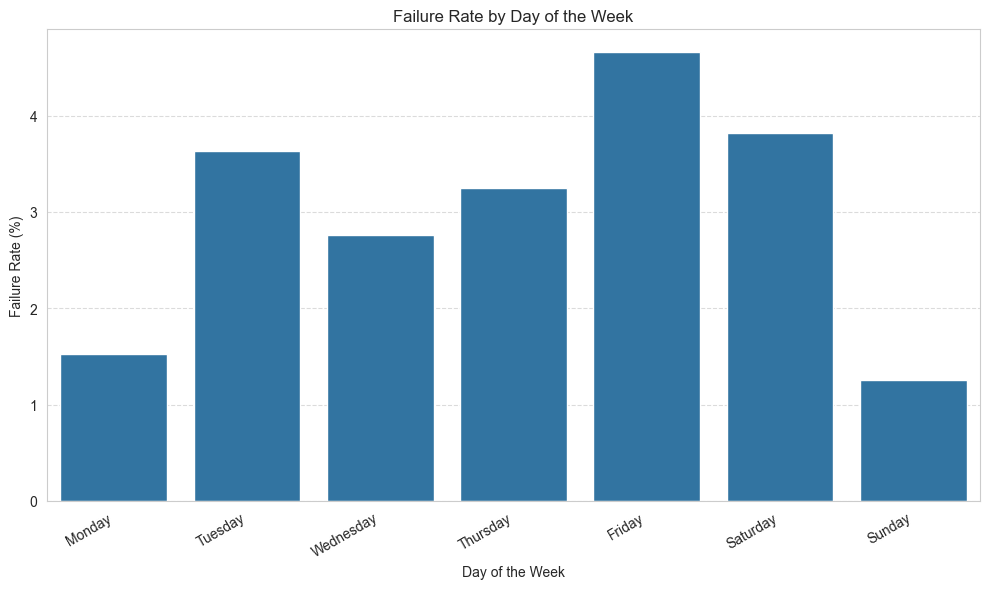

In [215]:

# failure vs hour
data['timestamp'] = pd.to_datetime(data['timestamp'])

DayOfWeek_failure = (
    data.assign(week=data['timestamp'].dt.day_name())
        .groupby('week', as_index=False)['failure']
        .mean()
        .rename(columns={'failure': 'failure_rate'})
)

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
DayOfWeek_failure['week'] = pd.Categorical(DayOfWeek_failure['week'], categories=day_order, ordered=True)
DayOfWeek_failure = DayOfWeek_failure.sort_values('week').reset_index(drop=True)

# IMPORTANT: keep as numeric for plotting
DayOfWeek_failure['failure_rate_pct'] = DayOfWeek_failure['failure_rate'] * 100

display(DayOfWeek_failure[['week', 'failure_rate_pct']].round(2).sort_values('week'))

barchart(data_df=DayOfWeek_failure, x_col='week', y_col='failure_rate_pct', title='Failure Rate by Day of the Week', xlabel='Day of the Week', ylabel='Failure Rate (%)')
# The highest failure day is Friday
# The lowest failure day is Sunday 

## Multivariate Analysis

### Correlation Analysis

In [216]:
Numerical_list = data.select_dtypes(include=[np.number]).columns.tolist()
display(Numerical_list)

['rated_power_kW',
 'wind_speed_mps',
 'wind_direction_deg',
 'turbulence_intensity',
 'air_density_kgm3',
 'ambient_temp_C',
 'humidity_pct',
 'power_output_kW',
 'rotor_speed_rpm',
 'generator_speed_rpm',
 'blade_pitch_angle_deg',
 'yaw_misalignment_deg',
 'gearbox_oil_temp_C',
 'gearbox_bearing_temp_C',
 'generator_bearing_temp_C',
 'generator_winding_temp_C',
 'main_bearing_temp_C',
 'nacelle_temp_C',
 'drivetrain_vibration_rms_mmps',
 'tower_vibration_mmps',
 'vib_fft_bearing_bpfo',
 'vib_fft_bearing_bpfi',
 'vib_fft_gearmesh',
 'vib_fft_sideband',
 'oil_particle_count',
 'oil_pressure_bar',
 'operating_hours_total',
 'cumulative_energy_MWh',
 'load_cycles',
 'hours_since_last_maintenance',
 'prior_fault_count',
 'component_age_days',
 'failure',
 'dayofweek',
 'hour']

,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,dayofweek,hour
rated_power_kW,1.000000e+00,-0.002194,0.035977,0.001536,0.002980,-0.002672,-0.004319,0.247409,-0.008566,-0.008493,0.012502,0.004708,-0.007722,-0.003773,0.003068,0.001589,-0.006703,-0.000655,-0.021238,-0.031670,3.407981e-02,-2.810089e-02,-4.205008e-02,-2.128792e-02,-3.694377e-02,0.020520,-0.098622,0.449739,-0.009589,0.173360,-0.154293,-0.014790,1.931181e-16,-4.514056e-15
wind_speed_mps,-2.194391e-03,1.000000,0.021026,0.240316,0.033147,-0.034523,0.013795,0.826093,0.911291,0.911398,-0.356584,0.002381,0.828751,0.831959,0.844621,0.888462,0.830212,0.180445,0.327269,0.547196,-2.228121e-02,-1.494207e-02,-6.342016e-03,-2.908254e-02,-1.630674e-02,-0.425079,0.005178,0.019543,0.003214,0.038976,-0.077774,-0.002206,-6.305544e-05,3.239047e-04
wind_direction_deg,3.597699e-02,0.021026,1.000000,0.006829,0.050877,-0.053473,0.000804,0.033329,0.018739,0.018661,-0.006330,0.000142,-0.014267,-0.017908,0.004424,0.013335,-0.002678,-0.045981,-0.094623,-0.007250,-8.519408e-02,-3.124740e-02,-2.111674e-02,-4.115754e-02,-1.069376e-01,0.039362,-0.032300,-0.009238,-0.211619,-0.051165,-0.038363,0.038811,-1.579851e-02,-1.071075e-02
turbulence_intensity,1.536220e-03,0.240316,0.006829,1.000000,0.014215,-0.015074,-0.002335,0.198890,0.218941,0.218912,-0.085736,0.001913,0.194920,0.196372,0.200601,0.211353,0.195866,0.036633,0.201390,0.129379,-7.201618e-03,-1.862293e-03,-1.292942e-03,-9.022854e-03,-5.377899e-03,-0.101528,-0.000239,0.004759,-0.000143,0.009556,-0.017866,0.001173,1.704003e-03,2.078565e-03
air_density_kgm3,2.980221e-03,0.033147,0.050877,0.014215,1.000000,-0.963602,-0.306225,0.037102,0.026612,0.026586,-0.008763,-0.001931,-0.240603,-0.216266,-0.219874,-0.058613,-0.270888,-0.928083,-0.000332,-0.029066,-5.491943e-02,-1.676954e-03,-2.423153e-02,-4.673093e-02,2.866594e-02,-0.053789,0.004399,0.004419,0.017183,0.011976,-0.012696,-0.000379,1.376343e-02,2.372743e-01
ambient_temp_C,-2.671723e-03,-0.034523,-0.053473,-0.015074,-0.963602,1.000000,0.317401,-0.037232,-0.028154,-0.028118,0.010333,0.002700,0.251315,0.225854,0.229848,0.062303,0.282716,0.963375,0.001332,0.030793,5.615740e-02,1.804346e-03,2.384395e-02,4.714331e-02,-2.932471e-02,0.055286,-0.001913,-0.002290,-0.018242,-0.013535,0.013682,0.000406,-1.501168e-02,-2.459213e-01
humidity_pct,-4.318675e-03,0.013795,0.000804,-0.002335,-0.306225,0.317401,1.000000,-0.010791,0.016788,0.016769,-0.008031,0.000499,0.090325,0.095470,0.096853,0.045389,0.100030,0.310592,-0.028905,0.020981,6.728353e-02,-9.893488e-02,2.293895e-02,2.661175e-02,-5.396138e-02,0.033428,-0.003981,-0.004523,-0.179498,0.184944,-0.107372,-0.005496,-6.935709e-03,-3.384360e-01
power_output_kW,2.474091e-01,0.826093,0.033329,0.198890,0.037102,-0.037232,-0.010791,1.000000,0.756667,0.756957,-0.163480,0.004353,0.843300,0.847520,0.859898,0.904722,0.845020,0.182497,0.330720,0.551213,-1.394655e-02,-1.142963e-02,-1.726493e-02,-3.336593e-02,-1.558828e-02,-0.430857,-0.002179,0.151592,0.007335,0.082208,-0.096270,-0.003252,1.737441e-03,5.252246e-03
rotor_speed_rpm,-8.565768e-03,0.911291,0.018739,0.218941,0.026612,-0.028154,0.016788,0.756667,1.000000,0.999840,-0.654872,0.002839,0.761496,0.764615,0.776172,0.815769,0.762825,0.169196,0.299418,0.501612,-1.927209e-02,-1.781400e-02,-3.829641e-03,-2.228520e-02,-1.731474e-02,-0.387324,-0.014365,-0.001929,0.000929,0.035192,-0.066498,0.003073,-1.130758e-03,7.482445e-04
generator_speed_rpm,-8.493180e-03,0

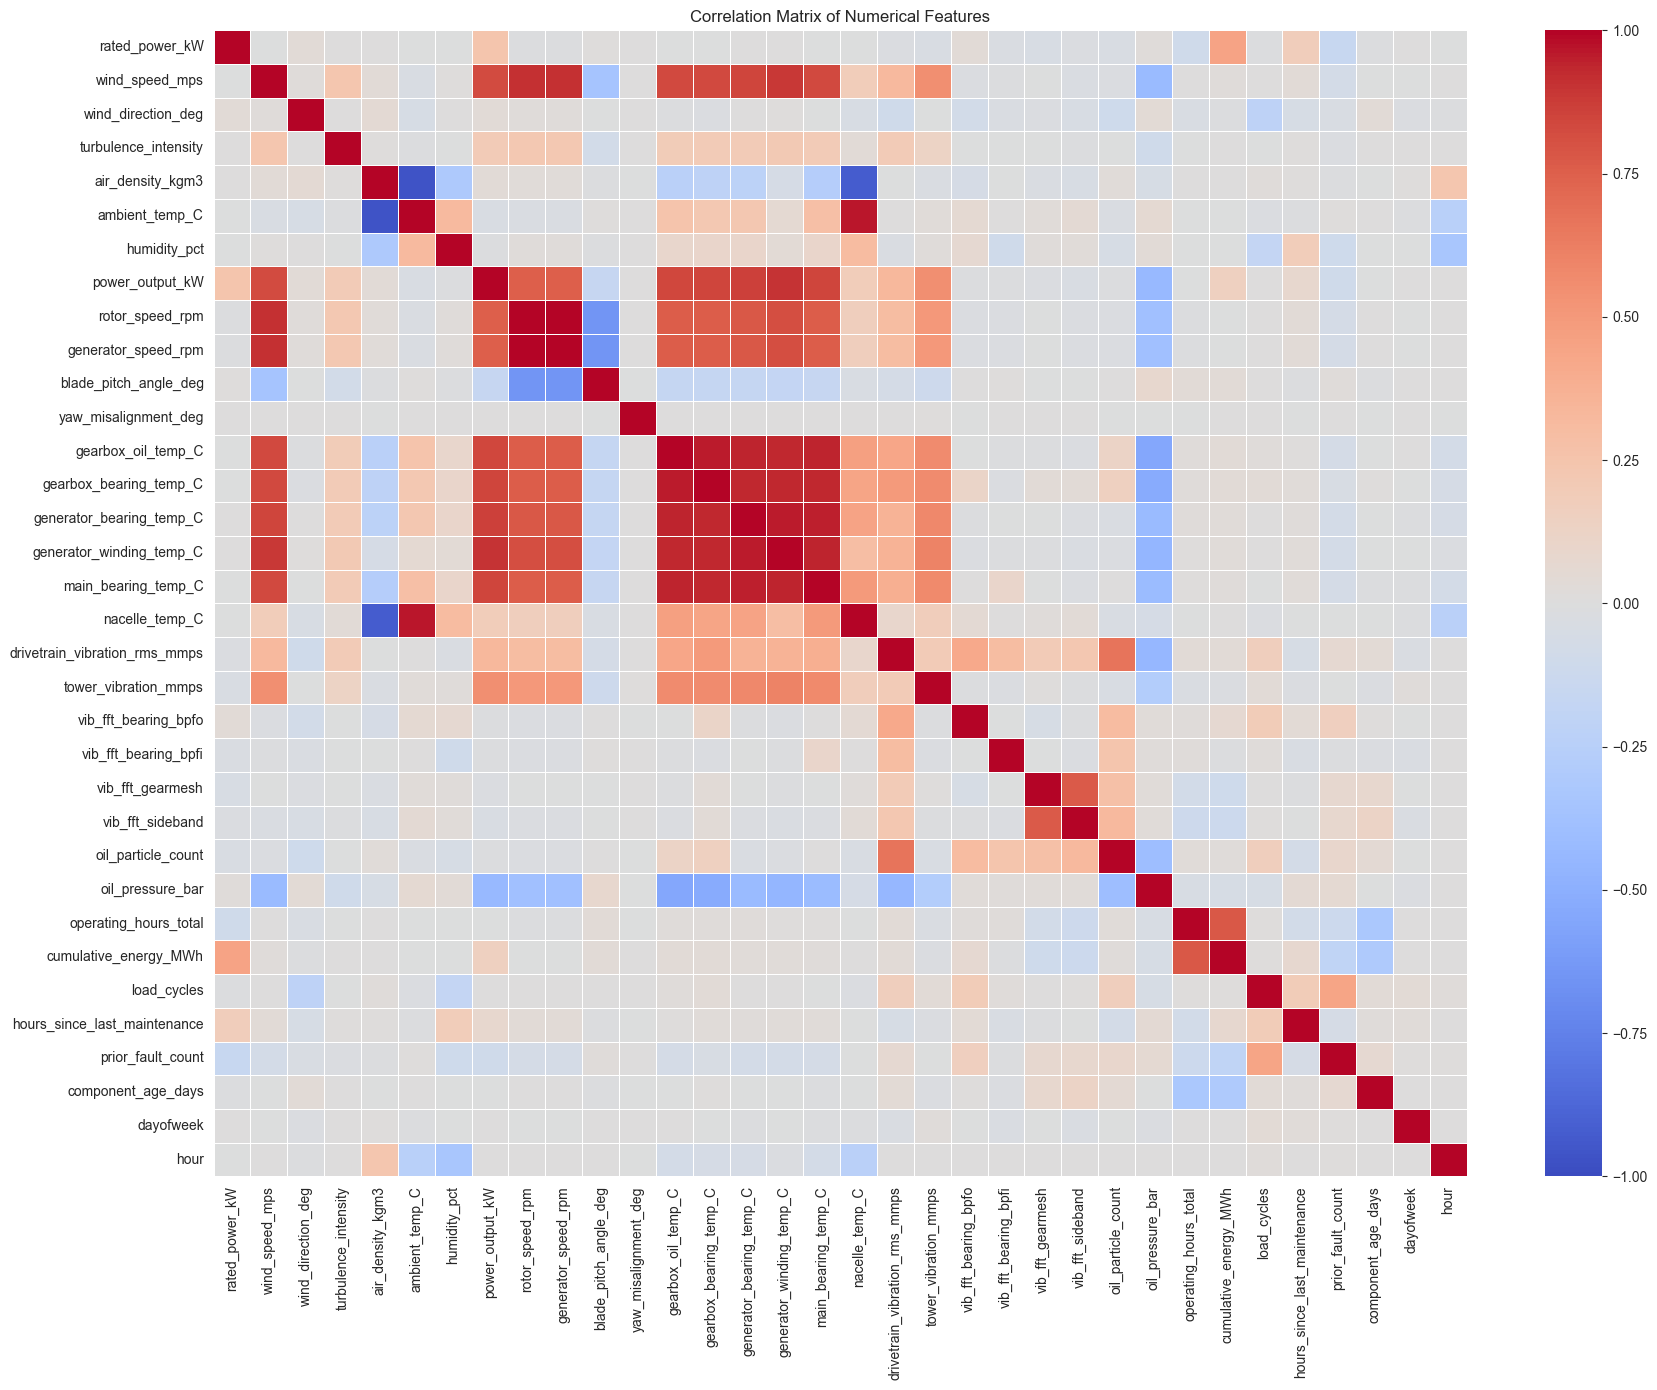

,feature_1,feature_2,correlation
236,rotor_speed_rpm,generator_speed_rpm,1.000
126,air_density_kgm3,ambient_temp_C,-0.964
166,ambient_temp_C,nacelle_temp_C,0.963
330,gearbox_oil_temp_C,gearbox_bearing_temp_C,0.960
371,generator_bearing_temp_C,generator_winding_temp_C,0.958
372,generator_bearing_temp_C,main_bearing_temp_C,0.952
390,generator_winding_temp_C,main_bearing_temp_C,0.943
333,gearbox_oil_temp_C,main_bearing_temp_C,0.941
331,gearbox_oil_temp_C,generator_bearing_temp_C,0.938
352,gearbox_bearing_temp_C,generator_winding_temp_C,0.937


In [217]:
# Select numerical feature columns for correlation analysis
# Exclude the target column to focus on feature relationships
feature_cols = [
    col for col in data.select_dtypes(include=[np.number]).columns
    if col != 'failure'
]

# Create correlation matrix
corr_matrix = data[feature_cols].corr()

# Display the full matrix
display(corr_matrix)

# Visualize the correlation matrix
plt.figure(figsize=(18, 14))
sns.heatmap(
    corr_matrix,
    annot=False,
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

# Identify highly correlated feature pairs
threshold = 0.85
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
)

high_corr = high_corr[
    high_corr['correlation'].abs() > threshold
].sort_values('correlation', key=lambda s: s.abs(), ascending=False)

display(high_corr.round(3))

# Interpretation notes
# - Values near +1 indicate strong positive correlation
# - Values near -1 indicate strong negative correlation
# - Values above |0.85| often suggest multicollinearity and may need review
#   before model building



# **Data Preprocessing**

## Splitting the data into train, validation, and test sets

In [218]:
#sort by time first and then by turbine id to ensure chronological order for each turbine
data = data.sort_values(by=['timestamp','turbine_id']).reset_index(drop=True)
display(data)

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure,dayofweek,dayofweek_name,hour,wind_speed_bin
0,2024-01-01 00:00:00,T001,1500,2.335,151.993,0.149,1.205,21.820,68.717,0.000,0.000,14.414,87.761,-5.455,53.728,56.728,57.637,61.546,48.728,29.820,1.518,0.974,0.455,0.391,0.455,0.399,55.756,6.032,19319.612,9587.146,0.000,769.284,0,1360.703,0,0,Monday,0,"(-0.017, 3.214]"
1,2024-01-01 00:00:00,T002,1500,12.335,209.358,0.201,1.286,0.000,70.379,1530.000,16.084,1440.075,1.307,-2.466,75.600,82.680,80.600,126.400,68.560,14.120,2.197,1.302,0.342,0.393,0.761,0.332,61.683,5.669,35966.367,19792.025,2.011,134.413,0,2169.811,0,0,Monday,0,"(9.611, 12.809]"
2,2024-01-01 00:00:00,T003,3600,8.132,174.780,0.150,1.257,8.002,56.061,683.976,11.403,1027.616,0.267,-4.830,53.901,57.661,58.500,70.700,48.521,17.142,1.428,0.967,0.342,0.384,0.501,0.369,66.520,5.945,30928.987,44843.545,1.505,1247.152,0,2133.545,0,0,Monday,0,"(6.412, 9.611]"
3,2024-01-01 00:00:00,T004,3000,4.465,226.115,0.223,1.195,20.391,53.238,15.659,7.271,645.807,0.098,3.022,53.313,56.334,57.293,61.483,48.302,28.422,1.851,1.102,0.383,0.330,0.577,0.221,54.612,6.167,41022.925,47109.405,2.229,78.902,0,1609.381,0,0,Monday,0,"(3.214, 6.412]"
4,2024-01-01 00:00:00,T005,1500,1.193,61.930,0.141,1.223,15.858,53.288,0.000,0.168,18.732,87.454,4.764,51.343,54.343,55.550,59.757,46.343,23.858,1.276,0.933,0.436,0.489,0.490,0.268,65.806,5.936,55708.022,28936.375,0.000,527.738,0,1906.679,0,0,Monday,0,"(-0.017, 3.214]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131755,2024-03-01 23:50:00,T011,3600,1.587,206.376,0.225,1.218,17.931,76.327,0.000,0.000,9.612,87.565,-4.898,53.990,59.510,59.632,58.520,45.612,26.366,1.623,1.124,0.441,0.345,0.433,0.289,58.509,6.202,12731.136,15003.070,13603.520,1049.000,53,1671.925,0,4,Friday,23,"(-0.017, 3.214]"
131756,2024-03-01 23:50:00,T012,2000,5.539,196.981,0.133,1.248,7.734,67.871,15.741,8.435,762.059,0.032,0.835,48.407,49.898,52.397,55.101,43.900,15.359,1.355,0.860,0.506,0.475,0.502,0.250,65.717,5.914,52943.181,44601.447,14059.791,797.333,22,514.529,0,4,Friday,23,"(3.214, 6.412]"
131757,2024-03-01 23:50:00,T013,2300,6.068,44.742,0.222,1.222,18.813,77.441,85.254,8.969,799.315,0.575,-1.966,56.546,57.656,51.945,63.191,50.012,26.957,1.719,0.847,0.359,0.325,0.471,0.238,69.639,6.261,17953.672,12744.366,13578.688,1087.500,106,1345.977,0,4,Friday,23,"(3.214, 6.412]"
131758,2024-03-01 23:50:00,T014,2000,3.271,323.271,0.219,1.283,3.019,68.975,0.000,5.709,514.621,-0.145,1.074,46.767,50.807,50.544,54.747,38.031,11.563,1.567,0.900,0.340,0.508,0.534,0.218,84.941,6.055,30496.581,25305.479,13768.716,2152.924,5,337.008,0,4,Friday,23,"(3.214, 6.412]"


In [219]:
n = len(data)

In [220]:
#This is me choosing my split boundries
i_train = int(n * 0.70)
i_val = int(n * 0.85)

# Uncomment the below train and validation indices to create a 90% train, 5% validation, and 5% test split.
# i_train = int(n * 0.90)
# i_val = int(n * 0.95)

# Uncomment the below train and validation indices to create a 80% train, 10% validation, and 10% test split.
# i_train = int(n * 0.80)
# i_val = int(n * 0.90)

In [221]:
data_train = data.iloc[:i_train] #70% of the data for training
data_val = data.iloc[i_train:i_val] #15% of the data for validation
data_test = data.iloc[i_val:]#15% of the data for testing, "Takes whatever is left for testing"

# Build X and y for training, validation, and testing datasets
# Drop failure column because that is the target variable
# Turbine_id, wind_speed_bin, and dayofweek_name are non-numeric and not usable as model features
columns_to_drop = ['failure', 'timestamp', 'turbine_id', 'wind_speed_bin', 'dayofweek_name']

X_train = data_train.drop(columns=columns_to_drop)
y_train = data_train['failure']

X_valid = data_val.drop(columns=columns_to_drop)
y_valid = data_val['failure']

X_test = data_test.drop(columns=columns_to_drop)
y_test = data_test['failure']

In [222]:
print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')
# Failure increases as time passes by for the turbines

print('X_train:', X_train.shape)
print('X_valid:', X_valid.shape)
print('X_test:', X_test.shape)

Train split failure rate: 1.60%
Validation split failure rate: 5.26%
Test split failure rate: 7.29%
X_train: (92232, 34)
X_valid: (19764, 34)
X_test: (19764, 34)


## Missing Value Treatment

In [223]:
# Calculate missing value percentages for each split
train_missing = (X_train.isna().sum() / len(X_train) * 100).round(2)
valid_missing = (X_valid.isna().sum() / len(X_valid) * 100).round(2)
test_missing = (X_test.isna().sum() / len(X_test) * 100).round(2)

# Create a comparison dataframe
missing_summary = pd.DataFrame({
    'Train (%)': train_missing,
    'Validation (%)': valid_missing,
    'Test (%)': test_missing
})

# Filter to show only columns with missing values
missing_summary = missing_summary[(missing_summary['Train (%)'] > 0) | 
                                   (missing_summary['Validation (%)'] > 0) | 
                                   (missing_summary['Test (%)'] > 0)]

display(missing_summary)

# Also show total counts
print("\n=== Missing Value Counts ===\n")
print("Training set:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])
print(f"\nValidation set:")
print(X_valid.isna().sum()[X_valid.isna().sum() > 0])
print(f"\nTest set:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

,Train (%),Validation (%),Test (%)
gearbox_oil_temp_C,0.50,0.49,0.46
generator_bearing_temp_C,0.52,0.54,0.54
oil_pressure_bar,0.47,0.51,0.51



=== Missing Value Counts ===

Training set:
gearbox_oil_temp_C          459
generator_bearing_temp_C    478
oil_pressure_bar            435
dtype: int64

Validation set:
gearbox_oil_temp_C           96
generator_bearing_temp_C    106
oil_pressure_bar            100
dtype: int64

Test set:
gearbox_oil_temp_C           90
generator_bearing_temp_C    106
oil_pressure_bar            101
dtype: int64


### `gearbox_oil_temp_C`

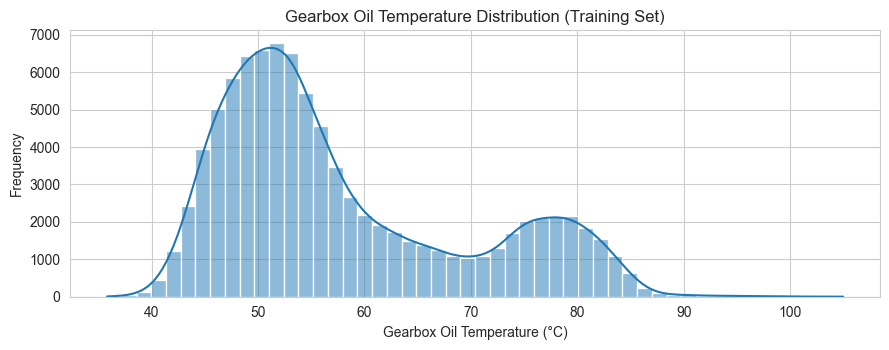

Median gearbox_oil_temp_C from training data: 53.92°C

Missing values after imputation:
  Training: 0
  Validation: 0
  Test: 0


In [224]:
histogram(X_train, 'gearbox_oil_temp_C', title='Gearbox Oil Temperature Distribution (Training Set)', xlabel='Gearbox Oil Temperature (°C)')
# The histogram shows a bimodal distribution with one dominant peak
# Strategy: Use median imputation (robust to the bimodal structure)

# Step 1: Calculate median from training data only
median_gearbox_oil_temp = X_train['gearbox_oil_temp_C'].median()

print(f"Median gearbox_oil_temp_C from training data: {median_gearbox_oil_temp:.2f}°C")

# Step 2: Fill missing values in all three datasets using the same median value
X_train['gearbox_oil_temp_C'].fillna(median_gearbox_oil_temp, inplace=True)
X_valid['gearbox_oil_temp_C'].fillna(median_gearbox_oil_temp, inplace=True)
X_test['gearbox_oil_temp_C'].fillna(median_gearbox_oil_temp, inplace=True)

# Step 3: Verifying no missing values remain
print(f"\nMissing values after imputation:")
print(f"  Training: {X_train['gearbox_oil_temp_C'].isna().sum()}")
print(f"  Validation: {X_valid['gearbox_oil_temp_C'].isna().sum()}")
print(f"  Test: {X_test['gearbox_oil_temp_C'].isna().sum()}")

### ```generator_bearing_temp_C```

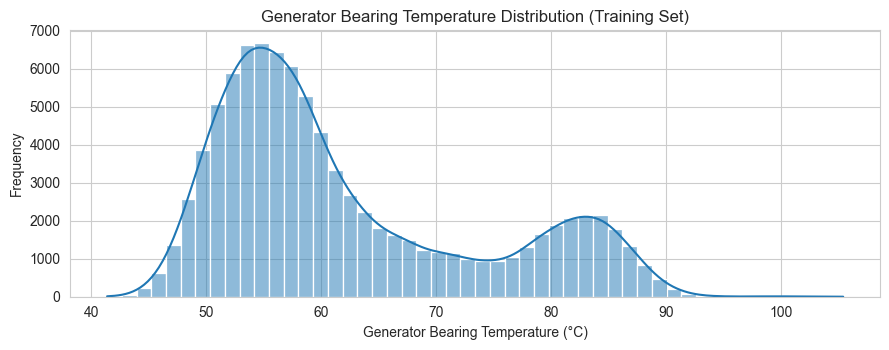

Median generator_bearing_temp_C from training data: 58.11°C

Missing values after imputation:
  Training: 0
  Validation: 0
  Test: 0


In [225]:
# Generating histogram to see the distribution of the feature
histogram(X_train, 'generator_bearing_temp_C', title='Generator Bearing Temperature Distribution (Training Set)', xlabel='Generator Bearing Temperature (°C)')
# Calculate median from training data only (same strategy as gearbox_oil_temp_C)
median_generator_bearing_temp = X_train['generator_bearing_temp_C'].median()

print(f"Median generator_bearing_temp_C from training data: {median_generator_bearing_temp:.2f}°C")

# Fill missing values in all three datasets using the same median value
X_train['generator_bearing_temp_C'].fillna(median_generator_bearing_temp, inplace=True)
X_valid['generator_bearing_temp_C'].fillna(median_generator_bearing_temp, inplace=True)
X_test['generator_bearing_temp_C'].fillna(median_generator_bearing_temp, inplace=True)

# Verify no missing values remain
print(f"\nMissing values after imputation:")
print(f"  Training: {X_train['generator_bearing_temp_C'].isna().sum()}")
print(f"  Validation: {X_valid['generator_bearing_temp_C'].isna().sum()}")
print(f"  Test: {X_test['generator_bearing_temp_C'].isna().sum()}")

### ```oil_pressure_bar```

Perform the following steps to handle missing values in the `oil_pressure_bar` feature:

1. Choose an imputation strategy (`mean`, `median`, or `mode`) based on the distribution of the feature.
2. Calculate the selected statistic using only the training data.
3. Use the calculated value to fill the missing values in the training, validation, and test datasets.
4. Apply the same imputation value across all three datasets to ensure a consistent preprocessing strategy and prevent data leakage.

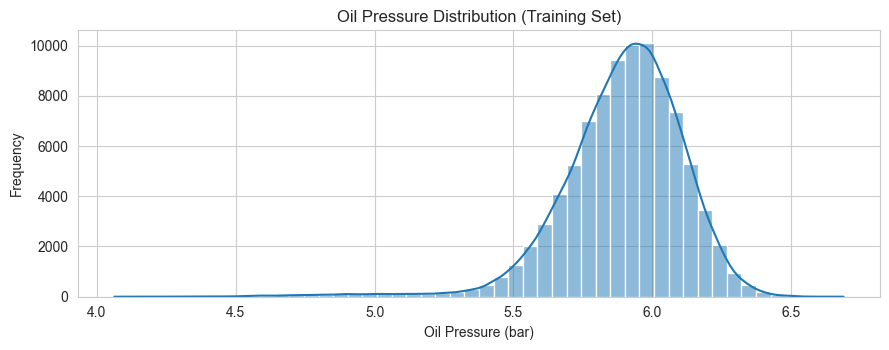

Median oil_pressure_bar from training data: 5.92 bar

Missing values after imputation:
  Training: 0
  Validation: 0
  Test: 0


In [226]:
# Generating histogram to see the distribution of the feature
histogram(X_train, 'oil_pressure_bar', title='Oil Pressure Distribution (Training Set)', xlabel='Oil Pressure (bar)')
# Calculate median because the left skewed distribution makes the median a better measure of central tendency than the mean
median_oil_pressure = X_train['oil_pressure_bar'].median()

print(f"Median oil_pressure_bar from training data: {median_oil_pressure:.2f} bar")

# Fill missing values in all three datasets using the same median value
X_train['oil_pressure_bar'].fillna(median_oil_pressure, inplace=True)
X_valid['oil_pressure_bar'].fillna(median_oil_pressure, inplace=True)
X_test['oil_pressure_bar'].fillna(median_oil_pressure, inplace=True)

# Verify no missing values remain
print(f"\nMissing values after imputation:")
print(f"  Training: {X_train['oil_pressure_bar'].isna().sum()}")
print(f"  Validation: {X_valid['oil_pressure_bar'].isna().sum()}")
print(f"  Test: {X_test['oil_pressure_bar'].isna().sum()}")
# **Model Building**

**Note**: All five models provided in the subsequent subsections need to be built and evaluated.

## Model Evaluation Criterion

In [227]:
# Uncomment one of the following evaluation metrics

# metric_of_choice = 'accuracy'
# metric_of_choice = 'precision'

#Utilize recall as my primary because recall is best to track how many actual failures the model catches because that is the most important thing in this model.
metric_of_choice = 'recall'
#Tuning prioritizes recall to ensure the model catches as many actual failures as possible

# metric_of_choice = 'f1'

## Utility Functions

In [228]:
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier (sklearn or tensorflow)
    predictors: independent variables
    target: dependent variable
    """

    # 1. Get raw predictions
    pred_raw = model.predict(predictors)

    # 2. Check the shape or values to handle DL vs ML models safely
    # If the predictions are probabilities (floats between 0 and 1, not exactly 0 or 1)
    # We check if any value falls strictly between 0 and 1
    if np.issubdtype(pred_raw.dtype, np.floating) and not np.all(np.isin(pred_raw, [0.0, 1.0])):
        # FOR TENSORFLOW DL MODELS: threshold the probabilities at 0.5
        pred = (pred_raw > 0.5).astype(int)
    else:
        # FOR SKLEARN ML MODELS: use them directly
        pred = pred_raw

    # Flatten predictions to ensure they match target shape perfectly
    pred = np.array(pred).flatten()

    # 3. Compute metrics
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # 4. Creating a dataframe of metrics
    data_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )

    return data_perf

In [229]:
def plot_confusion_matrix(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    # 1. Get raw predictions
    y_pred_raw = model.predict(predictors)

    # 2. Check if predictions are probabilities (typical for Keras/TF models or some ML models with predict_proba)
    # If y_pred_raw contains float values between 0 and 1, it's likely probabilities.
    if np.issubdtype(y_pred_raw.dtype, np.floating) and np.any((y_pred_raw > 0) & (y_pred_raw < 1)):
        # Binarize probabilities using a threshold (e.g., 0.5)
        y_pred = (y_pred_raw > 0.5).astype(int)
    else:
        # Use predictions directly (typical for scikit-learn classifiers that return binary labels)
        y_pred = y_pred_raw

    # Ensure y_pred is flattened to a 1D array, as confusion_matrix expects this format.
    y_pred = np.array(y_pred).flatten()

    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.show() # Added plt.show() to explicitly display the plot

## Decision Tree Classifier

Decision Tree - Training Performance


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


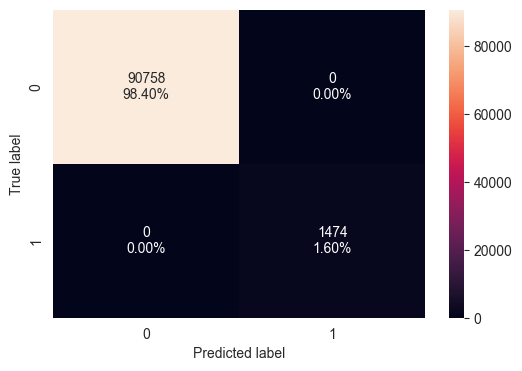

Decision Tree - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.955475,0.190568,0.835443,0.310345


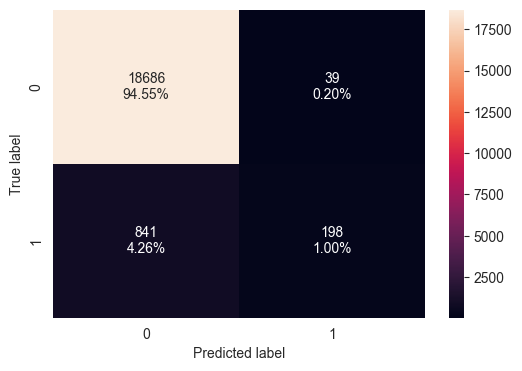

In [230]:
decision_tree = DecisionTreeClassifier(class_weight='balanced', random_state=42)

#Train the decision tree model on the training data
#Leanrs patterns from X_train using the corresponding labels y_train
decision_tree.fit(X_train, y_train)

print("Decision Tree - Training Performance")
decision_tree_train_performance = model_performance_classification(decision_tree, X_train, y_train)
display(decision_tree_train_performance)
plot_confusion_matrix(decision_tree, X_train, y_train)

print("Decision Tree - Validation Performance")
decision_tree_valid_performance = model_performance_classification(decision_tree, X_valid, y_valid)
display(decision_tree_valid_performance)
plot_confusion_matrix(decision_tree, X_valid, y_valid)

#The training and validation peformance suggest that the decison tree model is overfitting the training data. 
# The training performance metrics are significantly higher than the validation performance metrics.
# This indicates that the model has learned the training data too well and is not generalizing effectively to unseen data. 
# This overfitting can lead to poor performance on new, unseen data, as evidenced by the lower recall and precision scores on the validation set.

## Random Forest Classifier

Random Forest - Training Performance


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


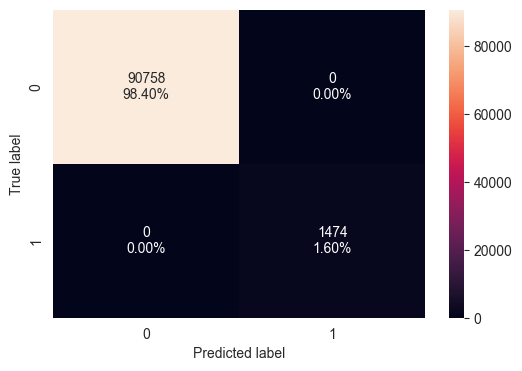

Random Forest - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.94829,0.025024,0.742857,0.048417


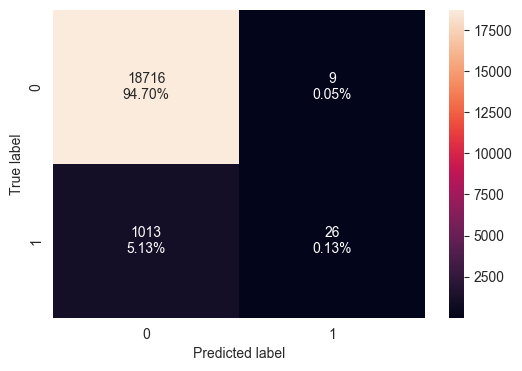

In [231]:
random_forest = RandomForestClassifier(class_weight='balanced', random_state=42)
random_forest.fit(X_train, y_train)

print("Random Forest - Training Performance")
random_forest_train_performance = model_performance_classification(random_forest, X_train, y_train)
display(random_forest_train_performance)
plot_confusion_matrix(random_forest, X_train, y_train)

print("Random Forest - Validation Performance")
random_forest_valid_performance = model_performance_classification(random_forest, X_valid, y_valid)
display(random_forest_valid_performance)
plot_confusion_matrix(random_forest, X_valid, y_valid)

#The training performance indicates overfitting due to the evaluation criterion all being '1.0'
#The validation performance shows a significant drop in metrics, especially recall and precision, which suggests that the model is not generalizing well to unseen data. 
# Overfitting can lead to poor performance on new, unseen data, as evidenced by the lower recall and precision scores on the validation set.

## Gradient Boosting Classifier

Gradient Boosting - Training Performance


,Accuracy,Recall,Precision,F1
0,0.998016,0.945047,0.931773,0.938363


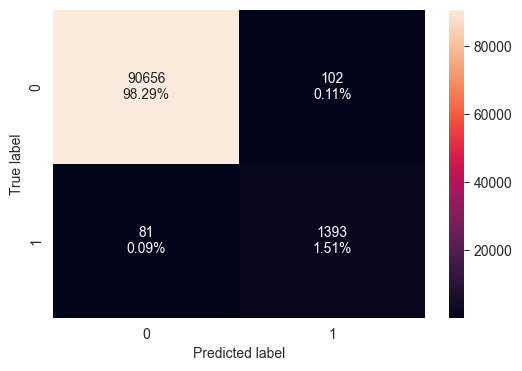

Gradient Boosting - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.946367,0.333975,0.485315,0.395667


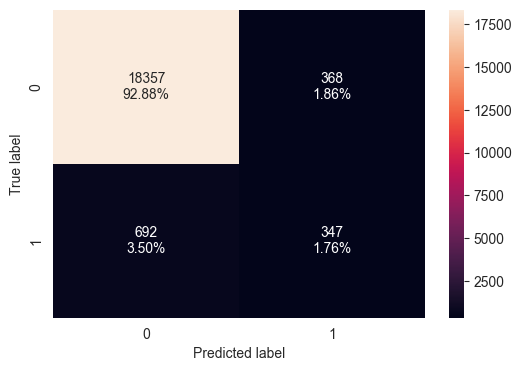

In [232]:
gradient_boosting = GradientBoostingClassifier(random_state=42)
gradient_boosting.fit(X_train, y_train)

print("Gradient Boosting - Training Performance")
gradient_boosting_train_performance = model_performance_classification(gradient_boosting, X_train, y_train)
display(gradient_boosting_train_performance)    
plot_confusion_matrix(gradient_boosting, X_train, y_train)

print("Gradient Boosting - Validation Performance")
gradient_boosting_valid_performance = model_performance_classification(gradient_boosting, X_valid, y_valid)
display(gradient_boosting_valid_performance)
plot_confusion_matrix(gradient_boosting, X_valid, y_valid)

#The training performance metrics for the Gradient Boosting model are relatively high, indicating that the model has learned the training data well. 
# However, the validation performance metrics show a noticeable drop, particularly in recall and precision. Misses more actual turbine failures and has a higher rate of false positives.
# Poor performance on validation which means not good with new/unseen dataThe decrease in recall is particularly concerning, as it indicates that the model is missing a significant number of actual failures in the validation set.

## XGBoost

Negative training samples: 90758
Positive training samples: 1474
scale_pos_weight: 61.573
XGBoost - Training Performance


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


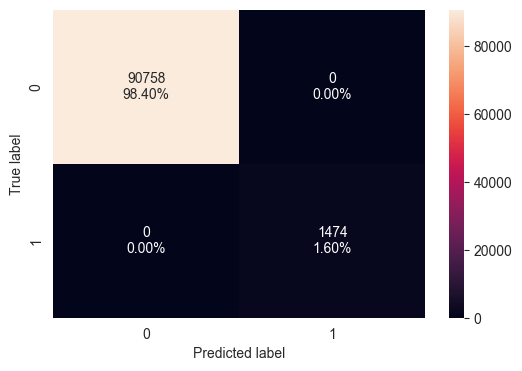

XGBoost - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.966049,0.487007,0.785714,0.601307


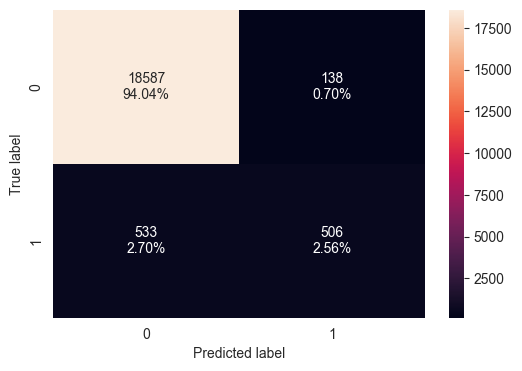

Recall change from training to validation: -0.5129932627526468
Precision change from training to validation: -0.2142857142857143


In [233]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

print(f"Negative training samples: {negative_count}")
print(f"Positive training samples: {positive_count}")
print(f"scale_pos_weight: {scale_pos_weight:.3f}")

xgboost_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
 )
xgboost_model.fit(X_train, y_train)

print("XGBoost - Training Performance")
xgboost_train_performance = model_performance_classification(xgboost_model, X_train, y_train)
display(xgboost_train_performance)
plot_confusion_matrix(xgboost_model, X_train, y_train)

print("XGBoost - Validation Performance")
xgboost_valid_performance = model_performance_classification(xgboost_model, X_valid, y_valid)
display(xgboost_valid_performance)
plot_confusion_matrix(xgboost_model, X_valid, y_valid)

print("Recall change from training to validation:", xgboost_valid_performance.loc[0, 'Recall'] - xgboost_train_performance.loc[0, 'Recall'])
print("Precision change from training to validation:", xgboost_valid_performance.loc[0, 'Precision'] - xgboost_train_performance.loc[0, 'Precision'])

# I gather that the XGBoost model is performing better than the previous models in terms of generalization. 
# The training performance metrics are high, but the validation performance metrics are descrease especially recall 
# This suggests that the model is able to capture the underlying patterns in the data without overfitting as much as the previous models. 
# BUT the drop in recall from training to validation indicates that the model is still missing some actual failures in the validation set, which is a concern for this application where catching failures is critical.

## Neural Networks(ANN) - Artificial Neural Network

In [234]:
tf.keras.backend.clear_session()

In [235]:
# Scale features to similar sizes so larger numbers do not dominate ANN training.
# Learn scaling values from training data only, then apply them to all three datasets(Training, Validation, Test).
scaler = StandardScaler()

# fit_transform calculates each training feature's mean and standard deviation, then scales the training data accordingly. 
# Standard deviation measures how spread out values are around the average.
# After scaling: 0 = at the training mean, 1 = one standard deviation above it,
# -1 = one standard deviation below it, and 2 = two above it (not limited to 0–1).
X_train_scaled = scaler.fit_transform(X_train)

# transform scales values using the training mean and standard deviation:
# scaled value = (value - training mean) / training standard deviation
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

print(f"Scaled training shape: {X_train_scaled.shape}")
print(f"Scaled validation shape: {X_valid_scaled.shape}")
print(f"Scaled test shape: {X_test_scaled.shape}")

Scaled training shape: (92232, 34)
Scaled validation shape: (19764, 34)
Scaled test shape: (19764, 34)


In [236]:
# Build a simple feed-forward neural network for binary classification.
model = Sequential([
    # The hidden layer learns patterns from the scaled turbine sensor features.
    # 32 neurons provide moderate learning capacity while limiting model complexity.
    # ReLU helps the network learn non-linear relationships efficiently.
    # the 1 in X_train_scaled.shape[1] represents the number of features in the input data.
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    
    # The output layer returns a probability between 0 and 1.
    # Values closer to 1 indicate a higher predicted probability of failure.
    Dense(1, activation='sigmoid')
])

In [237]:
display(model.summary())
# Dense param # is calculated using the formula: (input* neurons) + neurons
# Hidden Layer = (34 * 32) + 32
# Output Layer = (32 * 1) + 1

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

None

In [238]:
# Adam adapts the learning rate and usually converges faster than basic SGD.
# Binary cross-entropy is appropriate for predicting two classes: normal or failure.
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.BinaryAccuracy(name='binary_accuracy')
    ]
)

In [239]:
# Train for 50 complete passes through the training data.
# More epochs can improve learning, but too many may cause overfitting.
epochs = 75

# Process 32 samples before updating the network weights.
# Smaller batches provide frequent updates; larger batches are faster but use more memory.
batch_size = 32

In [240]:
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: weights[i] for i in range(len(weights))}

In [241]:
start = time.time()
history = model.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) , class_weight=class_weight_dict ,batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/75
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - binary_accuracy: 0.9456 - loss: 0.1250 - precision: 0.2236 - recall: 0.9715 - val_binary_accuracy: 0.9631 - val_loss: 0.1638 - val_precision: 0.6308 - val_recall: 0.7170
Epoch 2/75
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - binary_accuracy: 0.9794 - loss: 0.0386 - precision: 0.4363 - recall: 0.9993 - val_binary_accuracy: 0.9680 - val_loss: 0.1813 - val_precision: 0.6997 - val_recall: 0.6862
Epoch 3/75
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - binary_accuracy: 0.9849 - loss: 0.0299 - precision: 0.5143 - recall: 0.9986 - val_binary_accuracy: 0.9678 - val_loss: 0.1700 - val_precision: 0.7025 - val_recall: 0.6728
Epoch 4/75
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - binary_accuracy: 0.9875 - loss: 0.0257 - precision: 0.5610 - recall: 0.9986 - val_binary_accuracy: 0.9683 - val_loss: 0.2321 - val_precision: 0.7146 - val_recall: 0.6603
Epoch 5/75
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - binary_accuracy: 0.9888 - loss: 0.0244 -

In [242]:
print("Time taken in seconds ",end-start)

Time taken in seconds  389.3861401081085


ANN - Training Performance
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 2s 792us/step


,Accuracy,Recall,Precision,F1
0,0.996693,0.999322,0.828925,0.906183


ANN - Training Confusion Matrix
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 2s 716us/step


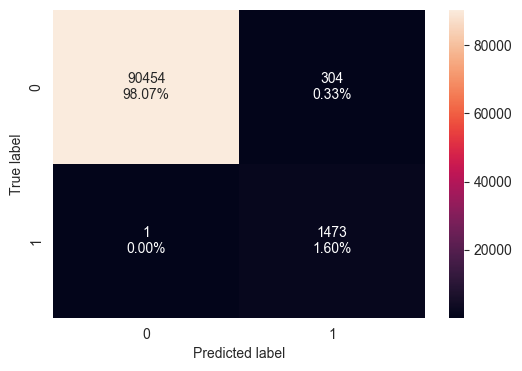

ANN - Validation Performance
618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 687us/step


,Accuracy,Recall,Precision,F1
0,0.967871,0.610202,0.733796,0.666316


ANN - Validation Confusion Matrix
618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 727us/step


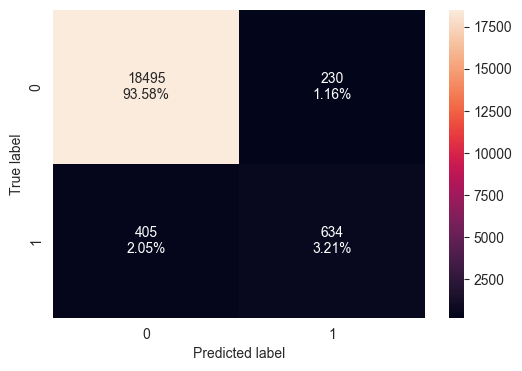

,Accuracy,Recall,Precision,F1
Training - Validation Gap,0.029,0.389,0.095,0.24


Training recall: 0.999
Validation recall: 0.610
Assessment: the ANN shows signs of overfitting because training recall is substantially higher than validation recall.


In [243]:
print("ANN - Training Performance")
ann_train_performance = model_performance_classification(model, X_train_scaled, y_train)
display(ann_train_performance)

print("ANN - Training Confusion Matrix")
plot_confusion_matrix(model, X_train_scaled, y_train)

print("ANN - Validation Performance")
ann_valid_performance = model_performance_classification(model, X_valid_scaled, y_valid)
display(ann_valid_performance)

print("ANN - Validation Confusion Matrix")
plot_confusion_matrix(model, X_valid_scaled, y_valid)

# Compare the primary metric and the other metrics across both datasets.
metric_gaps = (
    ann_train_performance.iloc[0] - ann_valid_performance.iloc[0]
).to_frame(name="Training - Validation Gap")
display(metric_gaps.T.round(3))

recall_gap = metric_gaps.loc["Recall", "Training - Validation Gap"]
train_recall = ann_train_performance.loc[0, "Recall"]
valid_recall = ann_valid_performance.loc[0, "Recall"]

print(f"Training recall: {train_recall:.3f}")
print(f"Validation recall: {valid_recall:.3f}")

if recall_gap > 0.10:
    print(
        "Assessment: the ANN shows signs of overfitting because training recall "
        "is substantially higher than validation recall."
    )
elif train_recall < 0.50 and valid_recall < 0.50:
    print(
        "Assessment: the ANN may be underfitting because recall is low on both "
        "the training and validation datasets."
    )
else:
    print(
        "Assessment: the ANN generalizes reasonably well because the training "
        "and validation recall values are relatively close."
    )

## **Baseline Model Performance Comparison**

### Training performance comparison

In [244]:
# Combine training performance metrics of all baseline models into a single table
training_performance_comparison = pd.concat(
    [
        decision_tree_train_performance,
        random_forest_train_performance,
        gradient_boosting_train_performance,
        xgboost_train_performance,
        ann_train_performance,
    ],
    ignore_index=True,
)

training_performance_comparison.index = [
    "Decision Tree", "Random Forest", "Gradient Boosting", "XGBoost", "ANN"
]

display(training_performance_comparison.sort_values(by=metric_of_choice.capitalize(), ascending=False))

# All baseline models show very high (often near-perfect) training recall/accuracy,
# which is expected since these are their training scores and several models are prone to overfitting.
# Training performance alone cannot be used to pick a final model - it must be compared against
# For training the best models for hyperparameter tuning will be Decision Tree and Random Forest, and XGBoost, as they show the highest training recall.

,Accuracy,Recall,Precision,F1
Decision Tree,1.000000,1.000000,1.000000,1.000000
Random Forest,1.000000,1.000000,1.000000,1.000000
XGBoost,1.000000,1.000000,1.000000,1.000000
ANN,0.996693,0.999322,0.828925,0.906183
Gradient Boosting,0.998016,0.945047,0.931773,0.938363


### Validation performance comparison

In [245]:
# Combine validation performance metrics of all baseline models into a single table
validation_performance_comparison = pd.concat(
    [
        decision_tree_valid_performance,
        random_forest_valid_performance,
        gradient_boosting_valid_performance,
        xgboost_valid_performance,
        ann_valid_performance,
    ],
    ignore_index=True,
)

validation_performance_comparison.index = [
    "Decision Tree", "Random Forest", "Gradient Boosting", "XGBoost", "ANN"
]

display(validation_performance_comparison.sort_values(by=metric_of_choice.capitalize(), ascending=False))

# Unlike training performance, validation performance exposes overfitting: Decision Tree and Random Forest
# collapse to very low recall on unseen data despite perfect training scores, while ANN and XGBoost retain
# the highest validation recall - making them the strongest candidates to carry forward into hyperparameter tuning.
# For validation the best model for hyperparameter tuning, we will focus on ANN and XGBoost as they have shown the highest validation recall.

,Accuracy,Recall,Precision,F1
ANN,0.967871,0.610202,0.733796,0.666316
XGBoost,0.966049,0.487007,0.785714,0.601307
Gradient Boosting,0.946367,0.333975,0.485315,0.395667
Decision Tree,0.955475,0.190568,0.835443,0.310345
Random Forest,0.948290,0.025024,0.742857,0.048417


# **Hyperparameter Tuning**

## XGBoost

In [246]:
# Hyperparameter search space for XGBoost
xgb_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6, 8],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.2, 0.3],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [0.1, 1, 5, 10],
}

In [247]:
xgb_random_search = RandomizedSearchCV(
    estimator=XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
    param_distributions=xgb_param_grid,
    n_iter=30,
    scoring=metric_of_choice,
    cv=5,
    random_state=42,
    n_jobs=-1,
)

xgb_random_search.fit(X_train, y_train)

print("Best XGBoost hyperparameters:")
print(xgb_random_search.best_params_)
print(f"\nBest cross-validation {metric_of_choice} score: {xgb_random_search.best_score_:.4f}")

Best XGBoost hyperparameters:
{'subsample': 0.9, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 100, 'min_child_weight': 7, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0.2, 'colsample_bytree': 0.9}

Best cross-validation recall score: 0.6349


XGBoost (Tuned) - Training Performance


,Accuracy,Recall,Precision,F1
0,0.98996,1.0,0.614167,0.760971


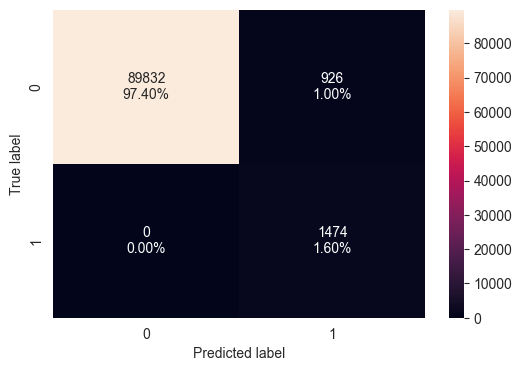

XGBoost (Tuned) - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.964481,0.907603,0.60878,0.728748


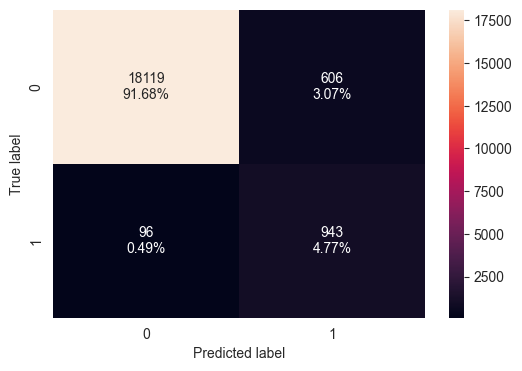

XGBoost (Tuned) - Test Performance


,Accuracy,Recall,Precision,F1
0,0.941611,0.850694,0.566081,0.6798


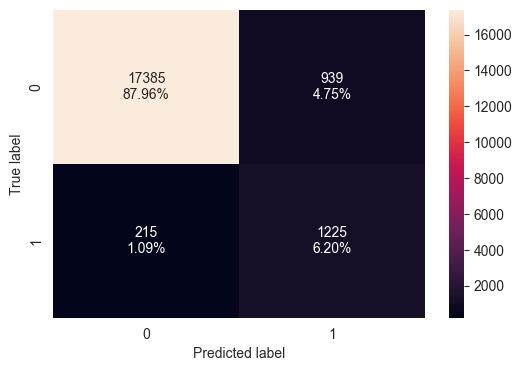

In [248]:
# RandomizedSearchCV already refits the best estimator on the full training data by default
xgboost_tuned_model = xgb_random_search.best_estimator_

print("XGBoost (Tuned) - Training Performance")
xgboost_tuned_train_performance = model_performance_classification(xgboost_tuned_model, X_train, y_train)
display(xgboost_tuned_train_performance)
plot_confusion_matrix(xgboost_tuned_model, X_train, y_train)

print("XGBoost (Tuned) - Validation Performance")
xgboost_tuned_valid_performance = model_performance_classification(xgboost_tuned_model, X_valid, y_valid)
display(xgboost_tuned_valid_performance)
plot_confusion_matrix(xgboost_tuned_model, X_valid, y_valid)

print("XGBoost (Tuned) - Test Performance")
xgboost_tuned_test_performance = model_performance_classification(xgboost_tuned_model, X_test, y_test)
display(xgboost_tuned_test_performance)
plot_confusion_matrix(xgboost_tuned_model, X_test, y_test)

## Neural Networks

In [249]:
tf.keras.backend.clear_session()

In [295]:
# Build a deeper, regularized feed-forward neural network for binary classification.
model1 = Sequential([
    # First hidden layer: wider capacity to learn richer patterns from the sensor features.
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),

    # Second hidden layer: narrower, refines the representation learned by the first layer.
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    # Output layer returns the probability of the positive (failure) class.
    Dense(1, activation='sigmoid')
])

In [296]:
display(model1.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,465 (9.63 KB)

 Trainable params: 2,337 (9.13 KB)

 Non-trainable params: 128 (512.00 B)

None

In [297]:
# Adam adapts the learning rate and usually converges faster than basic SGD.
# Binary cross-entropy is appropriate for predicting two classes: normal or failure.
model1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.BinaryAccuracy(name='binary_accuracy')
    ]
)

In [298]:
# Train for more passes since Batch Normalization and Dropout slow convergence and reduce overfitting risk.
epochs = 100

# Process 64 samples before updating the network weights.
batch_size = 64

In [299]:
start = time.time()
history = model1.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) ,class_weight=class_weight_dict, batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/100
1442/1442 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - binary_accuracy: 0.8546 - loss: 0.2797 - precision: 0.0932 - recall: 0.9281 - val_binary_accuracy: 0.9198 - val_loss: 0.3152 - val_precision: 0.3955 - val_recall: 0.9942
Epoch 2/100
1442/1442 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - binary_accuracy: 0.9616 - loss: 0.1082 - precision: 0.2911 - recall: 0.9783 - val_binary_accuracy: 0.9176 - val_loss: 0.3533 - val_precision: 0.3873 - val_recall: 0.9759
Epoch 3/100
1442/1442 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - binary_accuracy: 0.9684 - loss: 0.0840 - precision: 0.3342 - recall: 0.9844 - val_binary_accuracy: 0.9251 - val_loss: 0.3156 - val_precision: 0.4106 - val_recall: 0.9750
Epoch 4/100
1442/1442 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - binary_accuracy: 0.9709 - loss: 0.0734 - precision: 0.3535 - recall: 0.9898 - val_binary_accuracy: 0.9340 - val_loss: 0.2252 - val_precision: 0.4417 - val_recall: 0.9692
Epoch 5/100
1442/1442 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - binary_accuracy: 0.9737 - loss: 0.0

In [300]:
print("Time taken in seconds ",end-start)

Time taken in seconds  361.6085979938507


ANN (Tuned) - Training Performance
2883/2883 ━━━━━━━━━━━━━━━━━━━━ 3s 867us/step


,Accuracy,Recall,Precision,F1
0,0.993896,1.0,0.723613,0.839647


2883/2883 ━━━━━━━━━━━━━━━━━━━━ 2s 803us/step


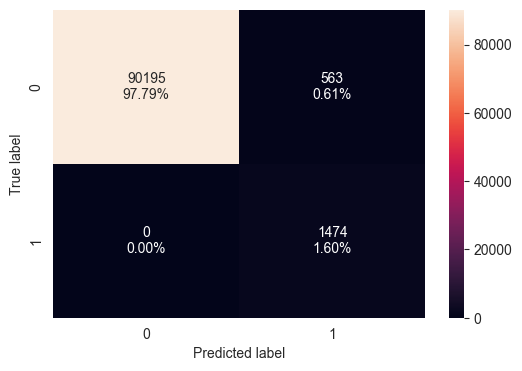

ANN (Tuned) - Validation Performance
618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step


,Accuracy,Recall,Precision,F1
0,0.972121,0.604427,0.817708,0.695075


618/618 ━━━━━━━━━━━━━━━━━━━━ 1s 998us/step


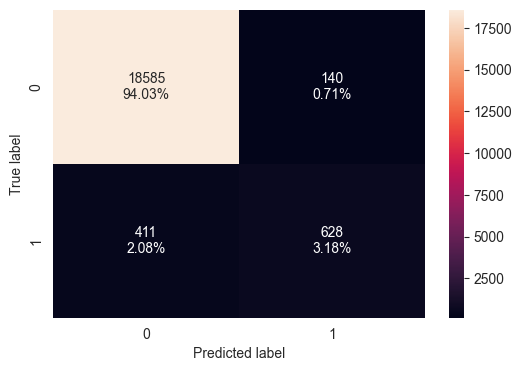

,Accuracy,Recall,Precision,F1
Training - Validation Gap,0.022,0.396,-0.094,0.145


Tuned ANN training recall: 1.000
Tuned ANN validation recall: 0.604
Assessment: the tuned ANN still shows signs of overfitting because training recall is substantially higher than validation recall.

Baseline ANN validation recall: 0.610
Tuned ANN validation recall: 0.604
Conclusion: the tuned architecture does not improve generalization - validation recall is not higher than the baseline ANN.


In [301]:
print("ANN (Tuned) - Training Performance")
ann_tuned_train_performance = model_performance_classification(model1, X_train_scaled, y_train)
display(ann_tuned_train_performance)
plot_confusion_matrix(model1, X_train_scaled, y_train)

print("ANN (Tuned) - Validation Performance")
ann_tuned_valid_performance = model_performance_classification(model1, X_valid_scaled, y_valid)
display(ann_tuned_valid_performance)
plot_confusion_matrix(model1, X_valid_scaled, y_valid)

# Compare the tuned ANN's own training vs. validation results
tuned_metric_gaps = (
    ann_tuned_train_performance.iloc[0] - ann_tuned_valid_performance.iloc[0]
).to_frame(name="Training - Validation Gap")
display(tuned_metric_gaps.T.round(3))

tuned_recall_gap = tuned_metric_gaps.loc["Recall", "Training - Validation Gap"]
tuned_train_recall = ann_tuned_train_performance.loc[0, "Recall"]
tuned_valid_recall = ann_tuned_valid_performance.loc[0, "Recall"]

print(f"Tuned ANN training recall: {tuned_train_recall:.3f}")
print(f"Tuned ANN validation recall: {tuned_valid_recall:.3f}")

# Use the same overfitting/underfitting logic applied to the baseline ANN
if tuned_recall_gap > 0.10:
    print(
        "Assessment: the tuned ANN still shows signs of overfitting because training "
        "recall is substantially higher than validation recall."
    )
elif tuned_train_recall < 0.50 and tuned_valid_recall < 0.50:
    print(
        "Assessment: the tuned ANN may be underfitting because recall is low on both "
        "the training and validation datasets."
    )
else:
    print(
        "Assessment: the tuned ANN generalizes reasonably well because the training "
        "and validation recall values are relatively close."
    )

# Directly compare validation recall against the baseline ANN to confirm actual improvement
baseline_valid_recall = ann_valid_performance.loc[0, "Recall"]
print(f"\nBaseline ANN validation recall: {baseline_valid_recall:.3f}")
print(f"Tuned ANN validation recall: {tuned_valid_recall:.3f}")

if tuned_valid_recall > baseline_valid_recall:
    print(
        "Conclusion: the tuned architecture improves generalization - it achieves "
        "higher validation recall than the baseline ANN, not just a smaller gap."
    )
else:
    print(
        "Conclusion: the tuned architecture does not improve generalization - "
        "validation recall is not higher than the baseline ANN."
    )

## Decision Tree

In [302]:
# Hyperparameter search space for Decision Tree
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2"],
}

In [303]:
dt_random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_distributions=dt_param_grid,
    n_iter=30,
    scoring=metric_of_choice,
    cv=5,
    random_state=42,
    n_jobs=-1,
)

dt_random_search.fit(X_train, y_train)

print("Best Decision Tree hyperparameters:")
print(dt_random_search.best_params_)
print(f"\nBest cross-validation {metric_of_choice} score: {dt_random_search.best_score_:.4f}")

Best Decision Tree hyperparameters:
{'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 3, 'criterion': 'gini'}

Best cross-validation recall score: 0.8162


In [304]:
# Retrieve the best Decision Tree, already refitted on the training data.
decision_tree_tuned_model = dt_random_search.best_estimator_

# Display the model and its optimized settings.
print("Best Decision Tree model:")
display(decision_tree_tuned_model)

print("\nOptimized hyperparameters:")
print(dt_random_search.best_params_)

print(f"\nBest cross-validation {metric_of_choice} score: "
      f"{dt_random_search.best_score_:.4f}")

Best Decision Tree model:


DecisionTreeClassifier(class_weight='balanced', max_depth=3,
                       max_features='sqrt', min_samples_leaf=5,
                       min_samples_split=5, random_state=42)


Optimized hyperparameters:
{'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 3, 'criterion': 'gini'}

Best cross-validation recall score: 0.8162


Decision Tree (Tuned) - Training Performance


,Accuracy,Recall,Precision,F1
0,0.981742,0.908412,0.463643,0.613939


Decision Tree (Tuned) - Training Confusion Matrix


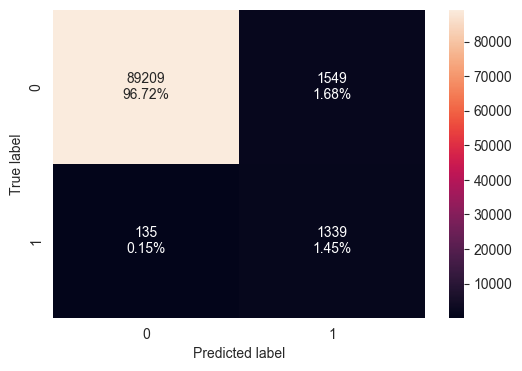

In [305]:
print("Decision Tree (Tuned) - Training Performance")
decision_tree_tuned_train_performance = model_performance_classification(
    decision_tree_tuned_model, X_train, y_train
)
display(decision_tree_tuned_train_performance)

print("Decision Tree (Tuned) - Training Confusion Matrix")
plot_confusion_matrix(decision_tree_tuned_model, X_train, y_train)

Decision Tree (Tuned) - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.929012,0.756497,0.405992,0.528403


Decision Tree (Tuned) - Validation Confusion Matrix


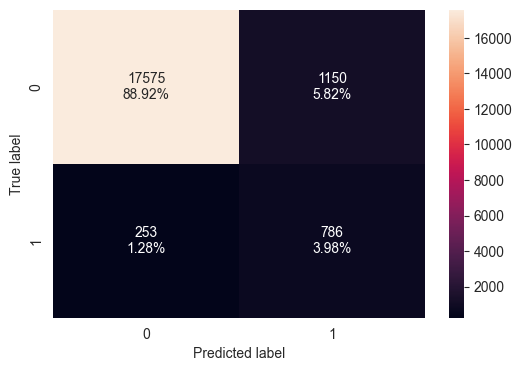

,Accuracy,Recall,Precision,F1
Training,0.982,0.908,0.464,0.614
Validation,0.929,0.756,0.406,0.528


Training recall: 0.908
Validation recall: 0.756
Training - validation recall gap: 0.152
Assessment: the tuned Decision Tree shows signs of overfitting.


In [306]:
print("Decision Tree (Tuned) - Validation Performance")
decision_tree_tuned_valid_performance = model_performance_classification(
    decision_tree_tuned_model, X_valid, y_valid
)
display(decision_tree_tuned_valid_performance)

print("Decision Tree (Tuned) - Validation Confusion Matrix")
plot_confusion_matrix(decision_tree_tuned_model, X_valid, y_valid)

performance_comparison = pd.concat(
    [
        decision_tree_tuned_train_performance.rename(index={0: "Training"}),
        decision_tree_tuned_valid_performance.rename(index={0: "Validation"}),
    ]
)
display(performance_comparison.round(3))

training_recall = decision_tree_tuned_train_performance.loc[0, "Recall"]
validation_recall = decision_tree_tuned_valid_performance.loc[0, "Recall"]
recall_gap = training_recall - validation_recall

print(f"Training recall: {training_recall:.3f}")
print(f"Validation recall: {validation_recall:.3f}")
print(f"Training - validation recall gap: {recall_gap:.3f}")

if recall_gap > 0.10:
    print("Assessment: the tuned Decision Tree shows signs of overfitting.")
elif training_recall < 0.50 and validation_recall < 0.50:
    print("Assessment: the tuned Decision Tree may be underfitting.")
else:
    print("Assessment: the tuned Decision Tree generalizes reasonably well.")

## Random Forest

In [307]:
# Optimized hyperparameter search space for faster tuning and better regularization
rf_param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [5, 8, 10, 15],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [2, 5, 10],
    "max_features": ["sqrt", "log2"],
}

In [308]:
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_distributions=rf_param_grid,
    n_iter=3,
    scoring=metric_of_choice,
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

rf_random_search.fit(X_train, y_train)

print("Best Random Forest hyperparameters:")
print(rf_random_search.best_params_)
print(f"\nBest cross-validation {metric_of_choice} score: "
      f"{rf_random_search.best_score_:.4f}")

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best Random Forest hyperparameters:
{'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 5}

Best cross-validation recall score: 0.6105


Random Forest (Tuned) - Training Performance


,Accuracy,Recall,Precision,F1
0,0.990643,1.0,0.630723,0.77355


Random Forest (Tuned) - Training Confusion Matrix


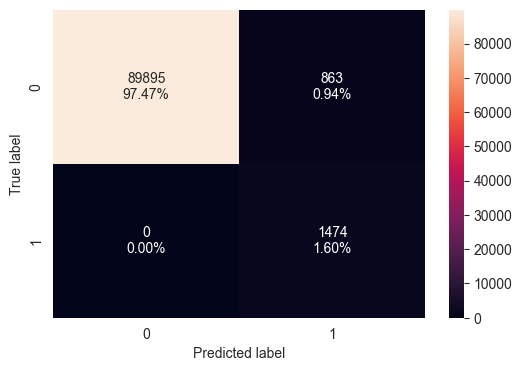

Random Forest (Tuned) - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.970198,0.652551,0.748344,0.697172


Random Forest (Tuned) - Validation Confusion Matrix


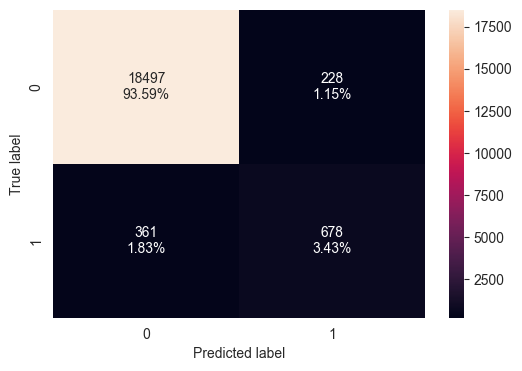

,Accuracy,Recall,Precision,F1
Training,0.991,1.000,0.631,0.774
Validation,0.970,0.653,0.748,0.697


Training recall: 1.000
Validation recall: 0.653
Training - validation recall gap: 0.347
Assessment: The tuned Random Forest shows signs of overfitting because training recall is substantially higher than validation recall.


In [309]:
# Retrieve the best-performing Random Forest model identified during randomized search
# (RandomizedSearchCV refits on the full training dataset by default)
random_forest_tuned_model = rf_random_search.best_estimator_

# Evaluate the retrained model on the training dataset
print("Random Forest (Tuned) - Training Performance")
random_forest_tuned_train_performance = model_performance_classification(
    random_forest_tuned_model, X_train, y_train
)
display(random_forest_tuned_train_performance)

print("Random Forest (Tuned) - Training Confusion Matrix")
plot_confusion_matrix(random_forest_tuned_model, X_train, y_train)

# Evaluate the retrained model on the validation dataset
print("Random Forest (Tuned) - Validation Performance")
random_forest_tuned_valid_performance = model_performance_classification(
    random_forest_tuned_model, X_valid, y_valid
)
display(random_forest_tuned_valid_performance)

print("Random Forest (Tuned) - Validation Confusion Matrix")
plot_confusion_matrix(random_forest_tuned_model, X_valid, y_valid)

# Compare training and validation results to assess generalization
rf_performance_comparison = pd.concat(
    [
        random_forest_tuned_train_performance.rename(index={0: "Training"}),
        random_forest_tuned_valid_performance.rename(index={0: "Validation"}),
    ]
)
display(rf_performance_comparison.round(3))

train_recall = random_forest_tuned_train_performance.loc[0, "Recall"]
valid_recall = random_forest_tuned_valid_performance.loc[0, "Recall"]
recall_gap = train_recall - valid_recall

print(f"Training recall: {train_recall:.3f}")
print(f"Validation recall: {valid_recall:.3f}")
print(f"Training - validation recall gap: {recall_gap:.3f}")

if recall_gap > 0.10:
    print("Assessment: The tuned Random Forest shows signs of overfitting because training recall is substantially higher than validation recall.")
elif train_recall < 0.50 and valid_recall < 0.50:
    print("Assessment: The tuned Random Forest may be underfitting because recall is low on both training and validation datasets.")
else:
    print("Assessment: The tuned Random Forest generalizes reasonably well to unseen data.")

## Gradient Boosting

In [310]:
# Hyperparameter search space for Gradient Boosting
gb_param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "max_features": ["sqrt", "log2"],
}

In [311]:
gb_random_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=gb_param_grid,
    n_iter=10,
    scoring=metric_of_choice,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

gb_random_search.fit(X_train, y_train)

print("Best Gradient Boosting hyperparameters:")
print(gb_random_search.best_params_)
print(f"\nBest cross-validation {metric_of_choice} score: "
      f"{gb_random_search.best_score_:.4f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Gradient Boosting hyperparameters:
{'subsample': 0.7, 'n_estimators': 150, 'max_features': 'sqrt', 'max_depth': 6, 'learning_rate': 0.05}

Best cross-validation recall score: 0.4712


Gradient Boosting (Tuned) - Training Performance


,Accuracy,Recall,Precision,F1
0,0.999761,0.992537,0.992537,0.992537


Gradient Boosting (Tuned) - Training Confusion Matrix


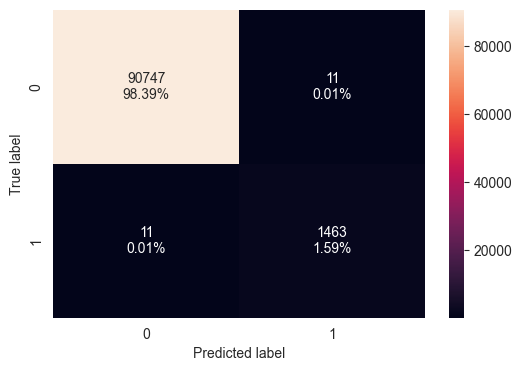

Gradient Boosting (Tuned) - Validation Performance


,Accuracy,Recall,Precision,F1
0,0.965746,0.470645,0.793831,0.590937


Gradient Boosting (Tuned) - Validation Confusion Matrix


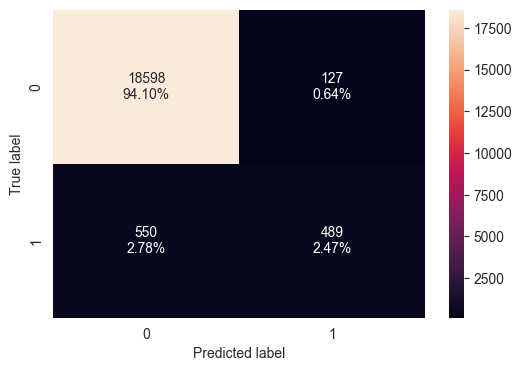

,Accuracy,Recall,Precision,F1
Training,1.000,0.993,0.993,0.993
Validation,0.966,0.471,0.794,0.591


Training recall: 0.993
Validation recall: 0.471
Training - validation recall gap: 0.522
Assessment: The tuned Gradient Boosting model shows signs of overfitting because training recall is substantially higher than validation recall.


In [312]:
# Retrieve the best-performing Gradient Boosting model identified during randomized search
# (RandomizedSearchCV refits on the full training dataset by default)
gradient_boosting_tuned_model = gb_random_search.best_estimator_

# Evaluate the retrained model on the training dataset
print("Gradient Boosting (Tuned) - Training Performance")
gradient_boosting_tuned_train_performance = model_performance_classification(
    gradient_boosting_tuned_model, X_train, y_train
)
display(gradient_boosting_tuned_train_performance)

print("Gradient Boosting (Tuned) - Training Confusion Matrix")
plot_confusion_matrix(gradient_boosting_tuned_model, X_train, y_train)

# Evaluate the retrained model on the validation dataset
print("Gradient Boosting (Tuned) - Validation Performance")
gradient_boosting_tuned_valid_performance = model_performance_classification(
    gradient_boosting_tuned_model, X_valid, y_valid
)
display(gradient_boosting_tuned_valid_performance)

print("Gradient Boosting (Tuned) - Validation Confusion Matrix")
plot_confusion_matrix(gradient_boosting_tuned_model, X_valid, y_valid)

# Compare training and validation results to assess generalization
gb_performance_comparison = pd.concat(
    [
        gradient_boosting_tuned_train_performance.rename(index={0: "Training"}),
        gradient_boosting_tuned_valid_performance.rename(index={0: "Validation"}),
    ]
)
display(gb_performance_comparison.round(3))

train_recall = gradient_boosting_tuned_train_performance.loc[0, "Recall"]
valid_recall = gradient_boosting_tuned_valid_performance.loc[0, "Recall"]
recall_gap = train_recall - valid_recall

print(f"Training recall: {train_recall:.3f}")
print(f"Validation recall: {valid_recall:.3f}")
print(f"Training - validation recall gap: {recall_gap:.3f}")

if recall_gap > 0.10:
    print("Assessment: The tuned Gradient Boosting model shows signs of overfitting because training recall is substantially higher than validation recall.")
elif train_recall < 0.50 and valid_recall < 0.50:
    print("Assessment: The tuned Gradient Boosting model may be underfitting because recall is low on both training and validation datasets.")
else:
    print("Assessment: The tuned Gradient Boosting model generalizes reasonably well to unseen data.")

# **Final Model Selection**

In [313]:
# Add tuned model training performance to the existing baseline comparison table
tuned_training_performance_comparison = pd.concat(
    [
        training_performance_comparison,
        decision_tree_tuned_train_performance.rename(index={0: "Decision Tree (Tuned)"}),
        random_forest_tuned_train_performance.rename(index={0: "Random Forest (Tuned)"}),
        gradient_boosting_tuned_train_performance.rename(index={0: "Gradient Boosting (Tuned)"}),
        xgboost_tuned_train_performance.rename(index={0: "XGBoost (Tuned)"}),
        ann_tuned_train_performance.rename(index={0: "ANN (Tuned)"}),
    ]
)

display(tuned_training_performance_comparison.sort_values(by=metric_of_choice.capitalize(), ascending=False))

# Quantify whether tuning changed training performance for each model
for name, tuned_perf, baseline_perf in [
    ("Decision Tree", decision_tree_tuned_train_performance, decision_tree_train_performance),
    ("Random Forest", random_forest_tuned_train_performance, random_forest_train_performance),
    ("Gradient Boosting", gradient_boosting_tuned_train_performance, gradient_boosting_train_performance),
    ("XGBoost", xgboost_tuned_train_performance, xgboost_train_performance),
    ("ANN", ann_tuned_train_performance, ann_train_performance),
]:
    tuned_score = tuned_perf.loc[0, metric_of_choice.capitalize()]
    baseline_score = baseline_perf.loc[0, metric_of_choice.capitalize()]
    change = tuned_score - baseline_score
    print(f"{name}: baseline {metric_of_choice} = {baseline_score:.3f}, tuned {metric_of_choice} = {tuned_score:.3f} (change: {change:+.3f})")

# Training performance alone cannot be used to pick a final model, since several models still show
# very high (often near-perfect) training scores - it must be compared against validation performance.

,Accuracy,Recall,Precision,F1
Decision Tree,1.000000,1.000000,1.000000,1.000000
Random Forest,1.000000,1.000000,1.000000,1.000000
XGBoost,1.000000,1.000000,1.000000,1.000000
ANN (Tuned),0.993896,1.000000,0.723613,0.839647
XGBoost (Tuned),0.989960,1.000000,0.614167,0.760971
Random Forest (Tuned),0.990643,1.000000,0.630723,0.773550
ANN,0.996693,0.999322,0.828925,0.906183
Gradient Boosting (Tuned),0.999761,0.992537,0.992537,0.992537
Gradient Boosting,0.998016,0.945047,0.931773,0.938363
Decision Tree (Tuned),0.981742,0.908412,0.463643,0.613939


Decision Tree: baseline recall = 1.000, tuned recall = 0.908 (change: -0.092)
Random Forest: baseline recall = 1.000, tuned recall = 1.000 (change: +0.000)
Gradient Boosting: baseline recall = 0.945, tuned recall = 0.993 (change: +0.047)
XGBoost: baseline recall = 1.000, tuned recall = 1.000 (change: +0.000)
ANN: baseline recall = 0.999, tuned recall = 1.000 (change: +0.001)


In [323]:
# Add tuned model validation performance to the existing baseline comparison table
tuned_validation_performance_comparison = pd.concat(
    [
        validation_performance_comparison,
        xgboost_tuned_valid_performance.rename(index={0: "XGBoost (Tuned)"}),
        ann_tuned_valid_performance.rename(index={0: "ANN (Tuned)"}),
    ]
)

display(tuned_validation_performance_comparison.sort_values(by=metric_of_choice.capitalize(), ascending=False))

# Compare each tuned model against its baseline counterpart on the metric of choice
for name, tuned_perf, baseline_perf in [
    ("XGBoost", xgboost_tuned_valid_performance, xgboost_valid_performance),
    ("ANN", ann_tuned_valid_performance, ann_valid_performance),
]:
    tuned_score = tuned_perf.loc[0, metric_of_choice.capitalize()]
    baseline_score = baseline_perf.loc[0, metric_of_choice.capitalize()]
    change = tuned_score - baseline_score
    print(f"{name}: baseline {metric_of_choice} = {baseline_score:.3f}, tuned {metric_of_choice} = {tuned_score:.3f} (change: {change:+.3f})")

,Accuracy,Recall,Precision,F1
XGBoost (Tuned),0.964481,0.907603,0.608780,0.728748
ANN,0.967871,0.610202,0.733796,0.666316
ANN (Tuned),0.972121,0.604427,0.817708,0.695075
XGBoost,0.966049,0.487007,0.785714,0.601307
Gradient Boosting,0.946367,0.333975,0.485315,0.395667
Decision Tree,0.955475,0.190568,0.835443,0.310345
Random Forest,0.948290,0.025024,0.742857,0.048417


XGBoost: baseline recall = 0.487, tuned recall = 0.908 (change: +0.421)
ANN: baseline recall = 0.610, tuned recall = 0.604 (change: -0.006)


In [ ]:
#Select the final model based on validation recall between the two tuned candidates
xgboost_tuned_valid_recall = xgboost_tuned_valid_performance.loc[0, "Recall"]
ann_tuned_valid_recall = ann_tuned_valid_performance.loc[0, "Recall"]

print(f"XGBoost (Tuned) validation recall: {xgboost_tuned_valid_recall:.3f}")
print(f"ANN (Tuned) validation recall: {ann_tuned_valid_recall:.3f}")

if xgboost_tuned_valid_recall >= ann_tuned_valid_recall:
    best_model = xgboost_tuned_model
    best_model_name = "XGBoost (Tuned)"
else:
    best_model = model1
    best_model_name = "ANN (Tuned)"

print(f"\nSelected final model: {best_model_name}")

XGBoost (Tuned) validation recall: 0.908
ANN (Tuned) validation recall: 0.604

Selected final model: XGBoost (Tuned)


## Feature Importance

In [325]:
def plot_feature_importances(model, X, y, feature_names=None, color="violet", figsize=(10, 10)):
    """
    Plots feature importances for both Traditional ML models (XGBoost, RF)
    and Deep Learning models (ANNs).

    Parameters:
    - model: Trained model object (XGBoost, Sklearn, Keras wrapper, etc.)
    - X: Evaluation features (DataFrame or 2D array)
    - y: Evaluation targets (Series or 1D array)
    - feature_names: List of feature names. If None and X is a DataFrame, uses X.columns.
    """
    # 1. Automatically grab feature names if not provided
    if feature_names is None:
        if hasattr(X, 'columns'):
            feature_names = X.columns
        else:
            feature_names = [f"Feature {i}" for i in range(X.shape[1])]

    # Convert X to numpy if it's a DataFrame for permutation calculation safety
    X_val = X.values if hasattr(X, 'columns') else X

    # 2. Extract or calculate importances
    if hasattr(model, 'feature_importances_'):
        print("💡 Detected Tree-based model. Extracting built-in feature importances...")
        importances = model.feature_importances_
        title = "Feature Importances (Tree-based Model)"
        xlabel = "Relative Importance"
    else:
        print("💡 Detected ANN/Black-box model. Calculating Permutation Importance...")
        # n_repeats is how many times a feature is shuffled; higher is more accurate but slower
        result = permutation_importance(model, X_val, y, n_repeats=5, random_state=42)
        importances = result.importances_mean
        title = "Feature Importances (Permutation Importance - ANN)"
        xlabel = "Mean Performance Drop when Shuffled"

    # 3. Sort the importances in ascending order
    indices = np.argsort(importances)

    # 4. Plotting
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.barh(range(len(indices)), importances[indices], color=color, align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()

💡 Detected Tree-based model. Extracting built-in feature importances...


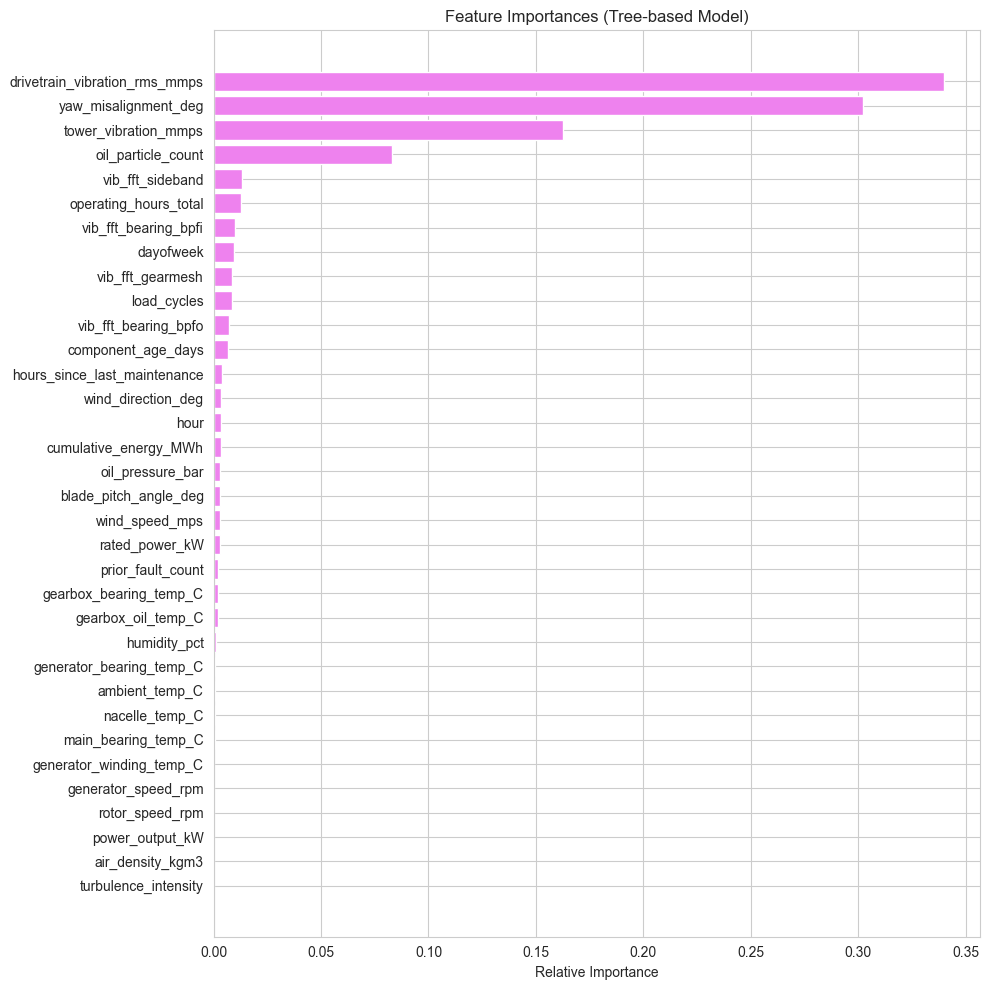

In [326]:
plot_feature_importances(best_model, X_train_scaled if best_model_name == "ANN (Tuned)" else X_train, y_train)

## Final Model Test Performance

XGBoost (Tuned) - Test Performance


,Accuracy,Recall,Precision,F1
0,0.941611,0.850694,0.566081,0.6798


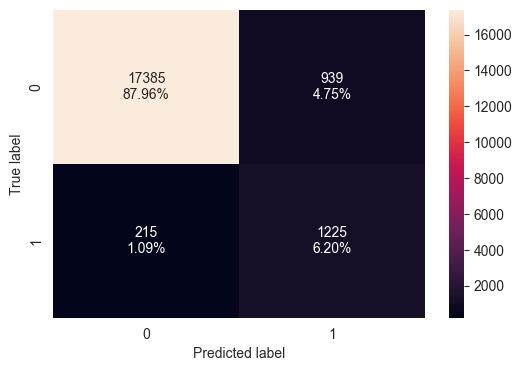

: 

In [ ]:
# The final model's evaluation inputs differ depending on whether it is tree-based (raw features) or the ANN (scaled features)
final_test_X = X_test_scaled if best_model_name == "ANN (Tuned)" else X_test

print(f"{best_model_name} - Test Performance")
final_test_performance = model_performance_classification(best_model, final_test_X, y_test)
display(final_test_performance)
plot_confusion_matrix(best_model, final_test_X, y_test)